# Imputation study on the expanded synthetic dataset

**PGS219 · measured/truth file pairs · out-of-fold evaluation**

This notebook fills missing cells in a synthetic asset dataset with several imputation models and compares the results. The dataset is synthetic so that noise, missingness and the relationships between columns are set in advance. That control supports three aims:

1. Test whether the models identify the relationships built into the data.
2. Find the conditions in which they fail: more noise, hidden inputs and removed predictors.
3. Compare the methods on accuracy, preserved distributions, stability and cost.

Models receive measured data only, with no description of the relationships. Truth is read only after fitting, for scoring. The results describe this synthetic dataset and do not establish performance on real SA Power Networks assets.

**To run:** create the environment once, select the kernel **Python (imputation)**, then use Restart and Run All.

```
conda create -n imputation python=3.12
conda activate imputation
pip install -r requirements.txt
python -m ipykernel install --user --name imputation --display-name "Python (imputation)"
```

## 1. Setup

The next cell loads the study code and sets the run options.

- `QUICK = True` runs every stage on a small sample with small models. It checks that the notebook works, and its numbers are not findings.
- `RESUME_RUN_ID` continues an interrupted run when set to its folder name.
- `EVALUATION_RUN_ID` starts from a finished run. Nothing is fitted, because saved predictions are loaded instead.

**To start from the evaluation:** set `EVALUATION_RUN_ID` to the run's folder name, run the next cell, then go straight to section 5. Run All also works and takes a few minutes, because the model sections load their saved results.

A run can be reused only if the data, the configuration and the code that produces predictions are unchanged. Evaluation code and figures can change freely.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/team19_asset_data").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
# A kernel left open keeps earlier versions of these modules, so they are always reloaded.
for name in [m for m in sys.modules if m.startswith("team19_asset_data.imputation_study")]:
    del sys.modules[name]

from team19_asset_data.imputation_study import evaluation as ev
from team19_asset_data.imputation_study import figures as fg
from team19_asset_data.imputation_study import relationships as rel
from team19_asset_data.imputation_study.columns import NUMERIC_TARGETS, TARGETS, column_table
from team19_asset_data.imputation_study.data import (
    audit_design, audit_fields, audit_files, discover, read_truth, relationship_residuals,
)
from team19_asset_data.imputation_study.models import CATEGORY_METHODS, NUMERIC_METHODS
from team19_asset_data.imputation_study.runner import (
    StudyConfig, default_workers, plan_table, quick_config,
)
from team19_asset_data.imputation_study.study import Study
from team19_asset_data.transformers.miceforest_compat import require_supported_version

QUICK = False
RESUME_RUN_ID = None
EVALUATION_RUN_ID = None
WORKERS = default_workers()

CONFIG = quick_config() if QUICK else StudyConfig()
ALL_SCENARIOS = discover(ROOT / CONFIG.data_directory)
SCENARIOS = {name: ALL_SCENARIOS[name] for name in (CONFIG.scenarios or sorted(ALL_SCENARIOS))}
REPRESENTATIVE = CONFIG.representative
NOISE_FREE, HIGH_NOISE = CONFIG.noise_series[0], CONFIG.noise_series[-1]

require_supported_version()
fg.apply_style()
pd.set_option("display.max_columns", None, "display.max_colwidth", 140, "display.width", 200,
              "display.max_rows", 200)
print("Mode:", "QUICK CHECK, not findings" if QUICK else "full study")
print("Scenarios:", len(SCENARIOS), "| worker processes:", WORKERS)

STUDY = Study(ROOT, CONFIG, SCENARIOS, WORKERS, RESUME_RUN_ID, EVALUATION_RUN_ID)
print("Run folder:", STUDY.directory)
print("Stage:", "evaluation of saved predictions" if EVALUATION_RUN_ID else "model fitting and evaluation")


Mode: full study
Scenarios: 9 | worker processes: 12
Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261105-234621
Stage: model fitting and evaluation


## 2. The dataset

### 2.1 How the data is built

The files describe 10,000 assets on a 100 × 100 grid, generated row by row in grid order. Installation days increase along that order. Each asset has a model, environmental exposures, three gas levels, a leakage rate and a remaining-life value. Each scenario has two tables:

- **truth**: the values before measurement error and before any cell is hidden.
- **measured**: the table a model sees, with measurement error and hidden cells.

The file name sets two controls:

- `completion` is the chance that a cell stays visible. Hiding is independent for every cell in every column, so the data is missing completely at random.
- `noise` is the bound of a uniform multiplicative error on the measured columns. `noise0.05` means a reading can be off by up to ±5%.

All nine scenarios describe the same assets. Each cell keeps one noise draw and one mask draw across scenarios, so a change between two scenarios comes from that control alone and can be measured on the same cells.

### 2.2 What each column means and how it is treated

The table below lists each column's meaning, type, valid range and error tolerance. These decisions follow from what a column represents and do not depend on patterns in the data.

In [2]:
with pd.option_context("display.max_colwidth", None):
    display(column_table())


,column,meaning,family,unit,scale,noisy,valid range,tolerance,treatment
0,x,Grid row of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,"Numeric coordinate, not a category. Predictions stay on the grid (rounded, 0-99). The zero point is arbitrary, so tolerance is in cells rather than percent."
1,y,Grid column of the asset location,location and date,grid cells,interval,no,0 to 99,±1 and ±5 grid cells,Same treatment as x.
2,install_date,"Installation day, counted from the start of the sequence",location and date,days,interval,no,0 to -,±7 and ±30 days,"Whole-day counter with no calendar origin, so it stays a number and is not converted to age. The origin is arbitrary, so tolerance is in days rather than percent."
3,model_id,Transformer model,asset condition,category,nominal,no,- to -,exact class,"Nominal label: the numbers 0-3 have no order. One-hot encoded as a predictor, with missing as its own level, and classified as a target. Never regressed or rounded."
4,altitude,Ground altitude at the location,location and date,synthetic units,interval,no,100 to 298,±1 and ±5 synthetic units,"Whole-number field limited to the range the grid can produce (100-298). Its zero point does not compare assets, so tolerance is in units rather than percent."
5,measured_humid,Humidity exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,"Noisy reading between 0 and 1 with a true zero, so percent tolerance is valid. Predictions are limited to that range. Scored against the noise-free truth."
6,measured_salt,Salt exposure reading,field reading,index,ratio,yes,0 to 1,±10% and ±15%,Same treatment as measured_humid.
7,measured_overgrowth,Vegetation overgrowth reading,field reading,index,ratio,yes,0 to 2,±10% and ±15%,"Floored at zero by definition, so exact zeros are real readings, not missing data. Percent tolerance cannot apply to a true zero; zero and positive cells are evaluated separately."
8,life,Remaining-life indicator,asset condition,synthetic units,ratio,no,0 to 100000,±100 and ±500 synthetic units,"Exact asset outcome. It sits in a narrow band just under its ceiling, where ±10% would accept almost any value, so tolerance is in units. Predictions cannot exceed the ceiling."
9,random_placebo,Random number unrelated to any other column,control,index,ratio,yes,0 to 1,±10% and ±15%,"Negative control, limited to 0-1. It is imputed and scored like any target, but any real gain over the median would be a false finding."


Tolerances differ between columns for these reasons:

- **Coordinates, days and altitude** have an arbitrary zero point, so a percentage would mean different things at different positions. They use absolute limits.
- **`life`** sits in a narrow band below its ceiling, where ±10% would accept almost any value. It also uses absolute limits.
- **Humidity, salt, overgrowth and the placebo** have a true zero and a wide relative range, so percentage limits apply.
- **Gas columns and `leakage`** vary less, so their percentage limits are tighter. `total_gas` varies least and has the tightest limits.

### 2.3 File audit

The next two cells check the files against their definitions: the shape of each pair, how much of each column is observed, and whether measurement error stays inside the bound in the file name. `measurement MAE` is the error already present in observed cells, which shows how far a reading sits from the truth.

,scenario,completion,noise,rows,columns,missing share,columns with missing cells
0,completion0.7-noise0.0,0.7,0.00,10000,15,0.2997,15
1,completion0.7-noise0.05,0.7,0.05,10000,15,0.2997,15
2,completion0.7-noise0.1,0.7,0.10,10000,15,0.2997,15
3,completion0.8-noise0.0,0.8,0.00,10000,15,0.1995,15
4,completion0.8-noise0.05,0.8,0.05,10000,15,0.1995,15
5,completion0.8-noise0.1,0.8,0.10,10000,15,0.1995,15
6,completion0.9-noise0.0,0.9,0.00,10000,15,0.0995,15
7,completion0.9-noise0.05,0.9,0.05,10000,15,0.0995,15
8,completion0.9-noise0.1,0.9,0.10,10000,15,0.0995,15


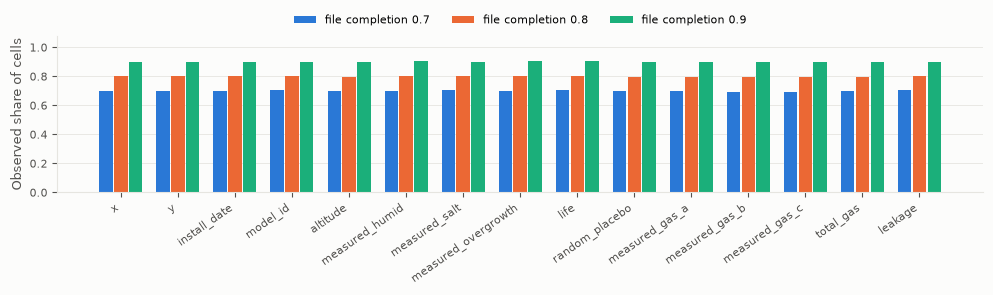

In [3]:
FILE_AUDIT = audit_files(ALL_SCENARIOS)
FIELD_AUDIT = audit_fields(ALL_SCENARIOS)
display(FILE_AUDIT.round(4))
fg.plot_missingness(FIELD_AUDIT, None)


In [4]:
noise_check = FIELD_AUDIT.groupby(["column", "noise"], sort=False).agg(
    changed=("changed share", "mean"),
    largest=("largest relative change", "max"),
    measurement_mae=("measurement MAE", "mean"),
).unstack("noise")
display(noise_check.round(4))

noise_free = FIELD_AUDIT[FIELD_AUDIT.noise.eq(0)]
inside_bound = (FIELD_AUDIT["largest relative change"] <= FIELD_AUDIT.noise + 1e-9).all()
never_noisy = FIELD_AUDIT[~FIELD_AUDIT["defined as noisy"]]["changed share"].eq(0).all()
print("Noise-free files equal the truth in every observed cell:", noise_free["changed share"].eq(0).all())
print("Every measured value lies inside the bound in its file name:", inside_bound)
print("Columns defined without noise are unchanged in every file:", never_noisy)


changed                 largest            measurement_mae                    
noise                  0.00    0.05    0.10    0.00  0.05 0.10            0.00      0.05      0.10
column                                                                                            
x                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
y                       0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
install_date            0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
model_id                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
altitude                0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
measured_humid          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0083    0.0166
measured_salt           0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0104    0.0208
measured_overgrowth     0.0  0.6773  0.6773     0.0  0.05  0.1             0.0    0.0083    0.0167
life                    0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
random_placebo          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0    0.0125    0.0251
measured_gas_a          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.2870  466.5740
measured_gas_b          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  243.3178  486.6355
measured_gas_c          0.0  1.0000  1.0000     0.0  0.05  0.1             0.0  233.6805  467.3610
total_gas               0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000
leakage                 0.0  0.0000  0.0000     0.0  0.00  0.0             0.0    0.0000    0.0000

Noise-free files equal the truth in every observed cell: True
Every measured value lies inside the bound in its file name: True
Columns defined without noise are unchanged in every file: True


The next cell confirms two things: scenarios can be compared cell by cell, and the truth follows the generator's definitions.

In [5]:
with pd.option_context("display.max_colwidth", None):
    display(audit_design(ALL_SCENARIOS))
display(relationship_residuals(read_truth(ALL_SCENARIOS[REPRESENTATIVE])))


,property,holds
0,Every file has the same truth,True
1,A completeness level hides the same cells at every noise level,True
2,Cells hidden at higher completeness are also hidden at lower completeness,True


,definition,largest residual
0,altitude = x + y + 100,0.000000e+00
1,"overgrowth = max(2 humid - salt, 0)",4.440892e-16
2,total_gas = gas a + b + c,1.273293e-11
3,life follows the formula of the row's model,4.365575e-11


### 2.4 Generator decisions

The dataset was regenerated after review with the generator's author. The earlier version is kept in `data/datasets_v1`.

- **Masking** covers all 15 columns. The first version covered only the first eight.
- **Noise** applies only to humidity, salt, overgrowth, the placebo and the three gas readings. `life`, `total_gas` and `leakage` are exact by design, so some columns stay reliable when others degrade.
- **Gas and `life`**: more gas reduces `life` for every model. The scale `total_gas/300000` is kept from the first version, so this term is small.
- **Model 0** uses `day_count` in its overgrowth term, matching the other models. The first version used an undefined variable.
- **Missingness** is completely at random only. The generator does not explore other mechanisms.

## 3. Experimental design

### 3.1 Targets and predictors

Every column has missing cells, so all 15 are imputation targets: 14 numeric columns and `model_id`. `random_placebo` is one of them and serves as the negative control: it is unrelated to every other column, so no model should predict it better than the median. For each target, every other column is a predictor.

### 3.2 Preprocessing

All fitted values, including means, scales and category levels, come from the training fold.

| Step | Decision | Reason |
|---|---|---|
| Missing predictors | Left as missing at the start | Each method handles gaps natively, so no fixed value is invented. Chained models then replace gaps with their own estimates. |
| Missing indicators | Not used | Masks are random, so an indicator carries no information about the value. |
| `model_id` as a predictor | One-hot for distance and linear models; a category or number for trees | It is nominal, so distances and coefficients must not read its numbers as an order. Trees can split it into its levels. |
| Row position | Never a feature | It would reveal the grid position, and it is not a property of an asset. |
| Predictions | Limited to the valid range; whole-number columns rounded | This follows from the column definitions. The raw value is kept, and section 5 reports how often this applied. |

### 3.3 Choosing settings

Every setting was chosen before this study, from a fixed list of candidates, by a rule fixed before the candidates were scored. Settings then stay the same in every scenario, so a change between scenarios is not caused by a change of settings.

- **Data:** the three scenarios at 0.7 completion. Masks are nested, so a cell visible there is visible in every scenario. No cell hidden in any scenario is read, and truth files are not read.
- **Score:** a further 10% of observed cells is hidden, and error on those cells is compared with the median's error. `random_placebo` is left out of the score.
- **Point models:** candidates more than 1% worse than the median on `random_placebo` are dropped. Of the rest, those within 0.002 of the best score are kept, and the fastest is chosen.
- **Donor-matched models:** candidates within 0.01 of the best band coverage are kept, and the one with the lowest point error is chosen.

Candidates included each model with no ridge base and with a straight-line base, and every chained model was offered the same range of passes. The second-order base scored best for every model. The rule and all scores are kept in `outputs/imputation-study/optimisation/clean_selection`.

### 3.4 Evaluation

Five folds are shared by all methods within a seed. A hidden cell is predicted by a model that never saw its row, and it is scored against the truth.

| Measure | Used for |
|---|---|
| MAE, RMSE, R², bias | Size and direction of error, in the column's own unit |
| Skill | Share of the median's MAE removed: 0 matches the median, 1 is perfect, below 0 is worse |
| Tolerance rate | Share within the column's tight and loose limits from section 2.2 |
| Exact rate | Share of whole-number columns recovered exactly |
| Accuracy, macro F1, balanced accuracy | `model_id`; log loss, Brier score and calibration gap for its probabilities |

MAE values are never averaged across columns because their units differ.

### 3.5 Experiments

The next cell lists the planned tasks. The experiments are described below the table.

In [6]:
display(plan_table(STUDY.plan))
print("Planned tasks:", len(STUDY.plan))


,experiment,tasks,scenarios,seeds,methods
0,main,945,9,1,8
1,stability,210,1,2,8
2,budget,10,1,1,2
3,pmm,70,1,1,1
4,joint,5,1,1,1
5,calibration,10,1,1,1
6,ablation,240,3,1,4
7,importance,90,3,1,2


Planned tasks: 1580


- **main**: every method in every scenario. A chained method is one task per fold, covering all its columns.
- **stability**: the representative scenario with two more fold seeds.
- **budget**: IterativeImputer at other pass limits, showing the effect of the number of passes.
- **pmm** and **joint**: repeated imputations in the representative scenario.
- **calibration**: the same forest with calibrated probabilities for `model_id`, with all predictors and without the gas columns.
- **ablation**: refits without a block of predictors, across the three noise levels at 0.8 completion. Targets inside the removed block are skipped.
- **importance**: permutation importance on held-out observed labels, from single-target forest and CatBoost models, because a chain covers every column at once.

## 4. Models

This chapter fits the models. When `EVALUATION_RUN_ID` is set, each section loads saved results in place of fitting. Each model has its own section with a short description, its setup, then its run and results. Sections run in order, starting with the baselines, because skill is measured against the median. Finished tasks are saved immediately, so an interruption loses only the tasks in progress. Model code never reads truth. Unless stated otherwise, tables show the representative scenario, `completion0.8-noise0.05`, which has moderate missingness and moderate noise.

**How the chained models work.** Sections 4.2 to 4.7 and 4.9 use chained imputation, and most of them add a ridge base:

1. The first pass predicts each column in turn from the others, starting from the original gaps. Each prediction is filled in straight away, so the next column can use it.
2. Later passes repeat this with the latest estimates, so every row is now complete.
3. In later passes, a ridge regression on the other columns and their second-order terms takes the smooth part of each column. Second-order terms are squares and pairwise products.
4. The local model (trees or neighbours) fits only what the ridge leaves. The prediction is the sum of the two.

A chain lets a hidden cell use estimates of the other hidden cells in its row. The ridge handles sums, which trees and neighbours can only approximate with many small steps. The local model handles thresholds and interactions. One fit covers every column, so settings are shared by all columns.

Where a model reports `model_id`, the value comes from a separate classifier on the original gaps, because a filled-in estimate looks as certain as a measurement. Section 3.3 explains how all settings were chosen.

### 4.1 Median and Mode

The baselines fill every hidden cell with one value from the training fold: the median for numeric targets and the most common class for `model_id`. They use no other column, so they cannot learn any relationship.

**Reading the results:** every other model needs to beat these to show that it has learned something. On `random_placebo`, the median is the correct answer.

In [7]:
STUDY.run_model("Median and Mode")
STUDY.show_model("Median and Mode")


Experiments: 825 tasks
82/825 tasks, 3 s
164/825 tasks, 3 s
246/825 tasks, 3 s
328/825 tasks, 3 s
410/825 tasks, 3 s
492/825 tasks, 4 s
574/825 tasks, 4 s
656/825 tasks, 4 s
738/825 tasks, 4 s
820/825 tasks, 4 s
825/825 tasks, 4 s


**Median · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,24.8884,28.7428,-0.0006,0.1658,0.0,0.0302,0.1085,0.0116
1,y,25.3187,29.0652,-0.0009,0.0348,0.0,0.0268,0.1010,0.0071
2,install_date,343.3320,397.3921,-0.0005,3.2955,0.0,0.0127,0.0471,0.0010
3,altitude,33.8737,41.2782,-0.0022,1.8260,0.0,0.0269,0.0930,0.0094
4,measured_humid,0.1730,0.2083,-0.0066,-0.0169,0.0,0.1048,0.1562,NaN
5,measured_salt,0.2117,0.2475,-0.0022,-0.0116,0.0,0.1029,0.1501,NaN
6,measured_overgrowth,0.3008,0.3821,-0.0954,-0.1128,0.0,0.0467,0.0720,NaN
7,life,290.0439,392.9534,-0.0423,79.0972,0.0,0.2329,0.8304,NaN
8,random_placebo,0.2530,0.2911,-0.0021,0.0126,0.0,0.1034,0.1502,NaN
9,measured_gas_a,1247.7975,1450.9424,-0.0505,-317.5190,0.0,0.0597,0.3916,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,Mode,1965,0.2809,0.1774,0.2483


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Median,630,6.072,0.801,0.011
1,Mode,45,0.490,0.057,0.012


Tasks: 825 | failed: 0 | with warnings: 0


### 4.2 K-nearest neighbours

KNN finds the rows most similar to the one being filled and averages their values. It assumes nothing about the form of a relationship, but it needs similar rows to exist.

**Setup:** six passes with the ridge base, using 80 neighbours weighted by distance. Columns are scaled so that no unit dominates the distance. The first pass compares only the cells two rows share; later passes compare complete rows. `model_id` enters as one-hot columns.

**Reading the results:** most of the gain over plain KNN comes from the ridge, so neighbours act here as a local correction. Every column counts equally in the distance, including unrelated ones such as `random_placebo`.

Experiments: 115 tasks
11/115 tasks, 303 s
22/115 tasks, 596 s
33/115 tasks, 857 s
44/115 tasks, 1101 s
55/115 tasks, 1367 s
66/115 tasks, 1593 s
77/115 tasks, 1789 s
88/115 tasks, 2049 s
99/115 tasks, 2250 s
110/115 tasks, 2406 s
115/115 tasks, 2415 s


**KNN imputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.6824,1.7911,0.9961,0.0603,0.9726,0.9106,0.9774,0.6191
1,y,4.8480,12.1888,0.8240,-0.6116,0.8085,0.7848,0.8207,0.5702
2,install_date,10.6929,24.8126,0.9961,0.2985,0.9689,0.6432,0.9377,0.0390
3,altitude,4.6932,12.0311,0.9149,-0.5619,0.8615,0.7822,0.8215,0.6256
4,measured_humid,0.0527,0.0824,0.8426,-0.0061,0.6956,0.4869,0.5680,NaN
5,measured_salt,0.1020,0.1464,0.6492,0.0036,0.5182,0.3408,0.4493,NaN
6,measured_overgrowth,0.0506,0.1053,0.9169,-0.0086,0.8317,0.6077,0.6920,NaN
7,life,42.8900,92.0560,0.9428,2.4396,0.8521,0.9285,0.9908,NaN
8,random_placebo,0.2565,0.2955,-0.0328,0.0119,-0.0138,0.0965,0.1487,NaN
9,measured_gas_a,151.5550,331.6535,0.9451,-3.0182,0.8785,0.9843,0.9863,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
8,KNN imputer,1965,0.9781,0.9771,0.9773


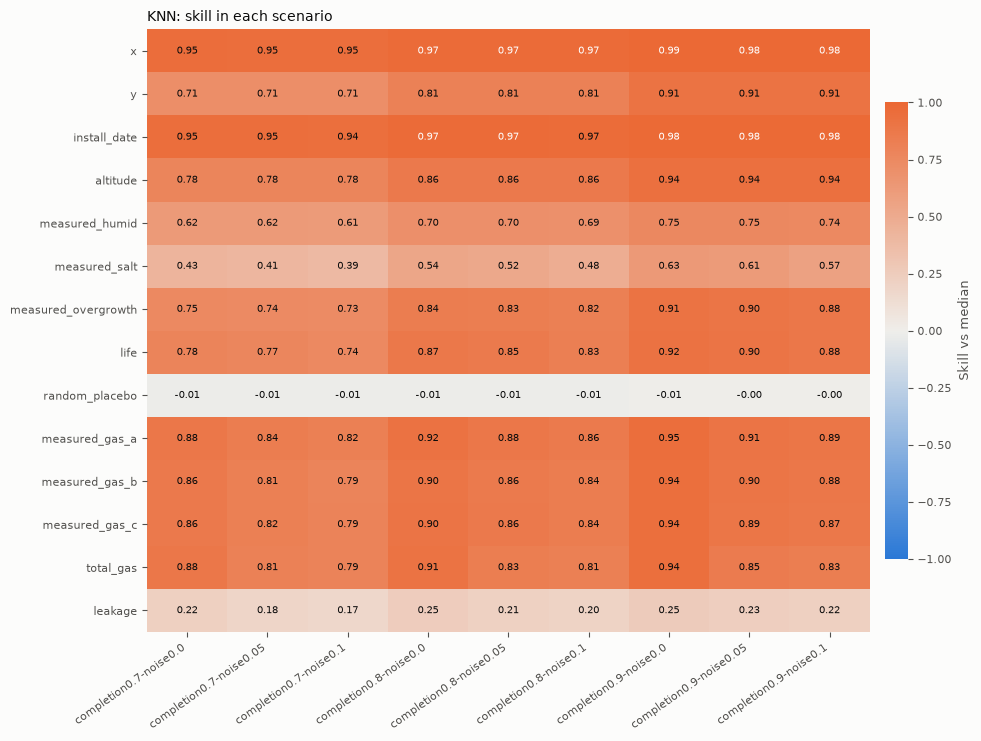

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
KNN imputer,0.9414,0.936,0.8966,0.9832,0.9781,0.945,0.997,0.996,0.9698


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,KNN imputer,45,5472.673,6881.869,18.303


Tasks: 115 | failed: 0 | with warnings: 0


In [8]:
STUDY.run_model("KNN")
STUDY.show_model("KNN")


### 4.3 IterativeImputer

IterativeImputer fills each column from the others and repeats. Here it uses only the ridge, with no local model, and covers the numeric columns.

**Setup:** ten passes on scaled columns. Straight-line terms have a penalty of 30 and second-order terms a penalty of 1,000, because the many second-order terms need a stronger penalty. Without a penalty, near-duplicate columns such as `altitude` and `x + y + 100` make the chain unstable. `model_id` enters as one-hot columns that stay empty when it is missing, so the chain estimates them too. Every estimate stays inside its column's observed training range, because squared terms otherwise feed on their own estimates and diverge.

**Reading the results:** the penalties trade exact recovery of sums for stability, so sums are recovered closely but not exactly. Second-order terms let this model handle `life` and the overgrowth threshold.

Experiments: 125 tasks
12/125 tasks, 9 s
24/125 tasks, 18 s
36/125 tasks, 28 s
48/125 tasks, 38 s
60/125 tasks, 49 s
72/125 tasks, 61 s
84/125 tasks, 68 s
96/125 tasks, 75 s
108/125 tasks, 80 s
120/125 tasks, 85 s
125/125 tasks, 86 s


**IterativeImputer · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.7482,1.9776,0.9953,0.0839,0.9699,0.9060,0.9794,0.5894
1,y,5.5323,13.9731,0.7687,-0.1798,0.7815,0.7778,0.8202,0.4904
2,install_date,11.3670,27.3045,0.9953,0.6057,0.9669,0.6158,0.9351,0.0380
3,altitude,5.3307,13.8548,0.8871,-0.1323,0.8426,0.7802,0.8235,0.5932
4,measured_humid,0.0583,0.0863,0.8273,-0.0057,0.6633,0.4370,0.5267,NaN
5,measured_salt,0.1132,0.1600,0.5811,0.0086,0.4655,0.3022,0.4148,NaN
6,measured_overgrowth,0.0584,0.1121,0.9058,-0.0076,0.8059,0.5594,0.6352,NaN
7,life,56.7300,102.6477,0.9289,4.7620,0.8044,0.8749,0.9918,NaN
8,random_placebo,0.2544,0.2925,-0.0122,0.0122,-0.0056,0.0980,0.1512,NaN
9,measured_gas_a,166.0035,295.5291,0.9564,-11.7370,0.8670,0.9501,0.9775,NaN


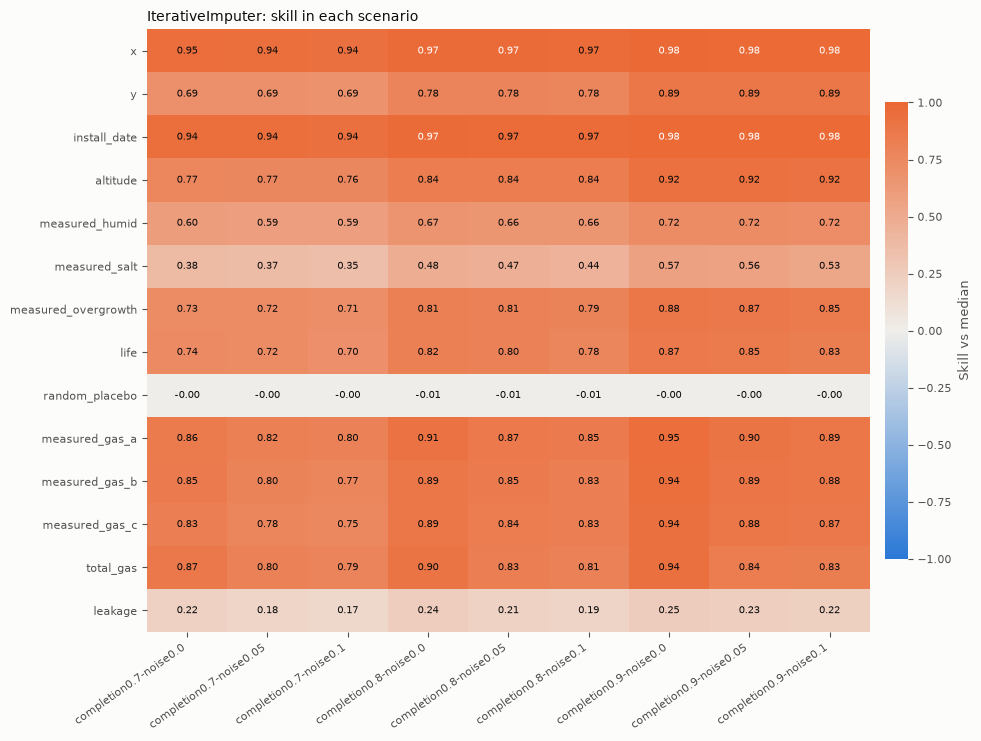

,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,IterativeImputer,45,408.689,7.526,0.661


Tasks: 125 | failed: 0 | with warnings: 125


In [9]:
STUDY.run_model("IterativeImputer")
STUDY.show_model("IterativeImputer")


**Number of passes.** The first table shows MAE on the same cells at other pass limits. The second shows the passes used in each scenario. A fit that stops at the limit has not converged, which is intended here. More passes help some columns and hurt others, and ten passes gave the best overall score when the settings were chosen.

In [10]:
iterative_numeric, _ = STUDY.scores_for("IterativeImputer")
budget, iterations = ev.budget_table(iterative_numeric, STUDY.logs["IterativeImputer"], STUDY.config)
display(budget.round(4))
display(iterations)


,MAE at limit 5,MAE at limit 10,MAE at limit 30
target,,,
x,0.9276,0.7482,0.6854
y,5.6929,5.5323,5.1944
install_date,14.0826,11.3670,10.5342
altitude,5.5206,5.3307,4.9871
measured_humid,0.0572,0.0583,0.0610
measured_salt,0.1113,0.1132,0.1184
measured_overgrowth,0.0586,0.0584,0.0605
life,57.1631,56.7300,57.6034
random_placebo,0.2544,0.2544,0.2544


,scenario,fits,fewest iterations,most iterations,fits stopped at the limit
0,completion0.7-noise0.0,5,10,10,5
1,completion0.7-noise0.05,5,10,10,5
2,completion0.7-noise0.1,5,10,10,5
3,completion0.8-noise0.0,5,10,10,5
4,completion0.8-noise0.05,5,10,10,5
5,completion0.8-noise0.1,5,10,10,5
6,completion0.9-noise0.0,5,10,10,5
7,completion0.9-noise0.05,5,10,10,5
8,completion0.9-noise0.1,5,10,10,5


### 4.4 Random Forest

Random Forest averages many decision trees, each grown on a sample of the rows. Averaging reduces the noise of single trees, and trees capture thresholds and interactions without being told about them. Run as a chain, it follows the style of MissForest.

**Setup:** four passes with the ridge base. Each column uses 100 trees grown on half of the rows, with at least two rows per leaf. Trees need no scaling and handle the gaps of the first pass themselves. `model_id` enters as a number, which trees can split into its four levels.

**Reading the results:** a forest alone cannot predict outside the range of its training labels. The ridge base can, which helps with sums such as `altitude`.

Experiments: 170 tasks
17/170 tasks, 14 s
34/170 tasks, 23 s
51/170 tasks, 28 s
68/170 tasks, 236 s
85/170 tasks, 377 s
102/170 tasks, 533 s
119/170 tasks, 682 s
136/170 tasks, 805 s
153/170 tasks, 946 s
170/170 tasks, 1043 s


**Random Forest · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.5744,1.8874,0.9957,0.0709,0.9769,0.9045,0.9784,0.7563
1,y,4.6369,11.9633,0.8304,-0.4500,0.8169,0.7843,0.8192,0.6747
2,install_date,9.5565,26.4563,0.9956,0.7354,0.9722,0.7775,0.9341,0.0907
3,altitude,4.5540,11.8359,0.9176,-0.3879,0.8656,0.7797,0.8215,0.6793
4,measured_humid,0.0428,0.0726,0.8778,-0.0001,0.7526,0.5897,0.6447,NaN
5,measured_salt,0.0894,0.1374,0.6913,-0.0017,0.5779,0.4173,0.5127,NaN
6,measured_overgrowth,0.0474,0.1013,0.9230,-0.0032,0.8426,0.6628,0.7218,NaN
7,life,35.9675,83.4695,0.9530,-0.4101,0.8760,0.9428,0.9928,NaN
8,random_placebo,0.2575,0.2975,-0.0468,0.0127,-0.0175,0.0980,0.1537,NaN
9,measured_gas_a,141.2617,307.0163,0.9530,-3.6194,0.8868,0.9883,0.9897,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
2,Random Forest,1965,0.9786,0.9774,0.9763


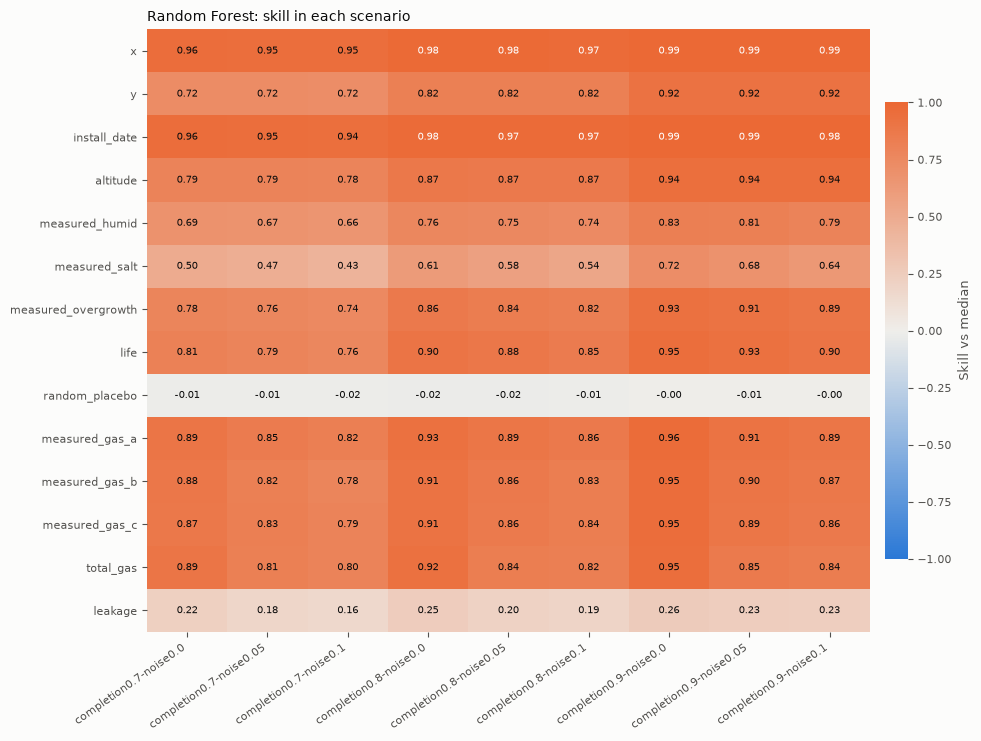

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Random Forest,0.9693,0.9673,0.937,0.9827,0.9786,0.9588,0.999,0.999,0.9779


,method,tasks,fit seconds,predict seconds,seconds per target and fold
2,Random Forest,45,5446.966,69.467,8.172


Tasks: 170 | failed: 0 | with warnings: 0


In [11]:
STUDY.run_model("Random Forest")
STUDY.show_model("Random Forest")


**Calibrated probabilities for `model_id`.** A confident prediction should be correct about as often as its probability says, and the calibration gap measures the difference. The comparison is repeated without the gas columns, because the task is otherwise too easy to separate the methods. The calibrated model uses the same forest settings as the raw result. It trains on inner folds, so it sees fewer rows for each fit.

In [12]:
display(ev.probability_table(STUDY.scored["Random Forest"], STUDY.config).round(4))


,predictors,method,n,accuracy,log loss,Brier,calibration gap,accuracy of most confident 50%
0,all predictors,Random Forest calibrated,1965,0.9807,0.0457,0.0257,0.0147,1.0000
2,all predictors,Random Forest,1965,0.9786,0.0844,0.0318,0.0468,1.0000
1,without gas columns,Random Forest calibrated,1965,0.7522,0.5654,0.3279,0.0399,0.9420
3,without gas columns,Random Forest,1965,0.7420,0.5825,0.3385,0.0857,0.9511


### 4.5 HistGradientBoosting

Gradient boosting builds trees one after another, each fitted to the error the earlier trees left. HistGradientBoosting first groups each column into bins, which makes it fast on data of this size.

**Setup:** six passes with the ridge base, using trees of up to 31 leaves. In the first pass, each split learns which side missing values should go to. Each regressor stops adding trees when error on 15% held-out rows stops falling, so a column with no signal gets few trees. `model_id` is a native categorical input.

**Reading the results:** boosting can fit fine detail, so it can also fit noise. The result on `random_placebo` shows how far that goes.

Experiments: 55 tasks
5/55 tasks, 47 s
10/55 tasks, 64 s
15/55 tasks, 91 s
20/55 tasks, 115 s
25/55 tasks, 138 s
30/55 tasks, 163 s
35/55 tasks, 186 s
40/55 tasks, 213 s
45/55 tasks, 235 s
50/55 tasks, 237 s
55/55 tasks, 266 s


**HistGradientBoosting · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.3874,1.8284,0.9960,0.0367,0.9844,0.9432,0.9849,0.8573
1,y,4.5854,12.0340,0.8284,-0.3247,0.8189,0.7884,0.8212,0.7566
2,install_date,7.1764,25.6273,0.9958,0.3350,0.9791,0.8550,0.9595,0.1237
3,altitude,4.5122,11.9163,0.9165,-0.3053,0.8668,0.7837,0.8225,0.7499
4,measured_humid,0.0432,0.0742,0.8722,-0.0015,0.7506,0.5837,0.6537,NaN
5,measured_salt,0.0887,0.1386,0.6859,0.0000,0.5811,0.4189,0.5147,NaN
6,measured_overgrowth,0.0457,0.1005,0.9243,-0.0016,0.8481,0.6697,0.7318,NaN
7,life,35.3523,85.2026,0.9510,-0.1550,0.8781,0.9433,0.9923,NaN
8,random_placebo,0.2552,0.2938,-0.0206,0.0121,-0.0086,0.0970,0.1477,NaN
9,measured_gas_a,150.9021,352.4413,0.9380,-0.2638,0.8791,0.9838,0.9843,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
4,HistGradientBoosting,1965,0.9807,0.9794,0.9794


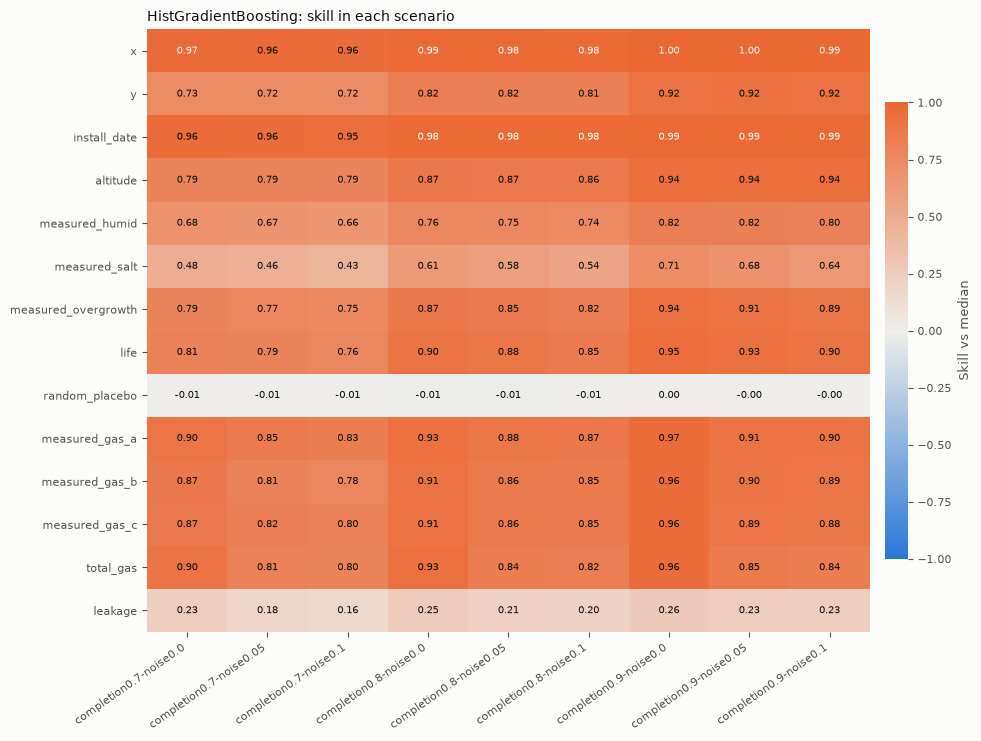

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
HistGradientBoosting,0.9693,0.9666,0.9441,0.9842,0.9807,0.9654,0.999,0.998,0.9869


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,HistGradientBoosting,45,2362.214,110.256,3.663


Tasks: 55 | failed: 0 | with warnings: 0


In [13]:
STUDY.run_model("HistGradientBoosting")
STUDY.show_model("HistGradientBoosting")


### 4.6 CatBoost

CatBoost is gradient boosting on symmetric trees, where every node at a given depth uses the same split. This acts as built-in regularisation.

**Setup:** six passes with the ridge base, using trees of depth four. Each regressor stops adding trees when error on 15% held-out rows has not improved for 30 rounds. Gaps in the first pass are handled natively. `model_id` enters as a number.

**Reading the results:** comparing this section with section 4.5 shows the effect of CatBoost's stronger regularisation on noisy targets.

Experiments: 160 tasks
16/160 tasks, 5 s
32/160 tasks, 8 s
48/160 tasks, 99 s
64/160 tasks, 230 s
80/160 tasks, 374 s
96/160 tasks, 492 s
112/160 tasks, 658 s
128/160 tasks, 732 s
144/160 tasks, 818 s
160/160 tasks, 901 s


**CatBoost · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,0.4186,1.9269,0.9955,0.0397,0.9832,0.9422,0.9794,0.8613
1,y,4.5313,11.8951,0.8324,-0.3919,0.8210,0.7884,0.8212,0.7621
2,install_date,7.5231,27.0784,0.9954,0.4881,0.9781,0.8702,0.9549,0.1277
3,altitude,4.4346,11.7812,0.9184,-0.3471,0.8691,0.7872,0.8265,0.7633
4,measured_humid,0.0436,0.0726,0.8778,-0.0019,0.7483,0.5766,0.6366,NaN
5,measured_salt,0.0927,0.1416,0.6719,-0.0007,0.5623,0.3864,0.4970,NaN
6,measured_overgrowth,0.0457,0.0994,0.9259,-0.0013,0.8479,0.6598,0.7387,NaN
7,life,35.8383,83.6171,0.9528,-2.5886,0.8764,0.9402,0.9928,NaN
8,random_placebo,0.2546,0.2930,-0.0157,0.0122,-0.0063,0.0975,0.1507,NaN
9,measured_gas_a,151.2448,351.6281,0.9383,8.4428,0.8788,0.9848,0.9858,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
3,CatBoost,1965,0.9791,0.9778,0.9778


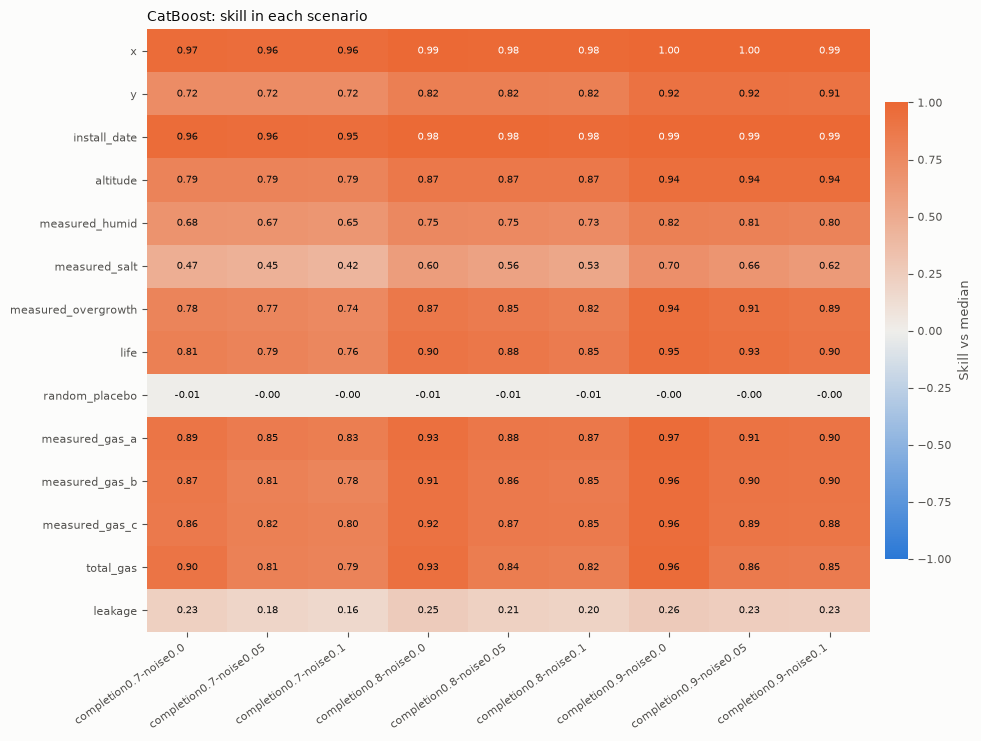

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
CatBoost,0.9666,0.9626,0.935,0.9837,0.9791,0.9598,0.999,0.999,0.9839


,method,tasks,fit seconds,predict seconds,seconds per target and fold
1,CatBoost,45,4843.594,16.998,7.201


Tasks: 160 | failed: 0 | with warnings: 0


In [14]:
STUDY.run_model("CatBoost")
STUDY.show_model("CatBoost")


### 4.7 miceforest direct

miceforest runs chained equations with LightGBM, another gradient boosting library. This section uses the model's predictions directly, without donor matching and without the ridge base. The project's audited compatibility patch for miceforest 6.0.5 is used throughout.

**Setup:** three passes of 200 boosting rounds, with each tree seeing 70% of the columns. miceforest's defaults are changed in two ways. It normally starts from random values, which would feed the first models with noise, so here it starts from the gaps. It also normally runs a depth-limited random forest that ignores the learning rate, so here it runs true gradient boosting.

**Reading the results:** this section is the reference for sections 4.8 and 4.9, which share this engine and add donor matching.

Experiments: 55 tasks
5/55 tasks, 13 s
10/55 tasks, 13 s
15/55 tasks, 26 s
20/55 tasks, 26 s
25/55 tasks, 38 s
30/55 tasks, 38 s
35/55 tasks, 39 s
40/55 tasks, 51 s
45/55 tasks, 51 s
50/55 tasks, 60 s
55/55 tasks, 61 s


**miceforest direct · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,1.1643,2.6869,0.9913,0.1492,0.9532,0.8271,0.9417,0.5452
1,y,5.4485,11.9258,0.8315,-0.4030,0.7848,0.5197,0.8162,0.2020
2,install_date,17.5058,38.8466,0.9904,0.7577,0.9490,0.5884,0.8642,0.0578
3,altitude,5.1308,11.6613,0.9200,-0.1641,0.8485,0.6315,0.8180,0.2576
4,measured_humid,0.0481,0.0758,0.8667,0.0009,0.7217,0.5353,0.6124,NaN
5,measured_salt,0.0954,0.1413,0.6736,0.0041,0.5493,0.3864,0.4944,NaN
6,measured_overgrowth,0.0562,0.1080,0.9125,0.0040,0.8132,0.5747,0.6613,NaN
7,life,44.3172,88.4735,0.9472,-0.2024,0.8472,0.9127,0.9934,NaN
8,random_placebo,0.2557,0.2959,-0.0355,0.0127,-0.0105,0.1064,0.1492,NaN
9,measured_gas_a,143.1308,277.8758,0.9615,-17.6410,0.8853,0.9824,0.9863,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
3,miceforest direct,1965,0.9837,0.9827,0.9828


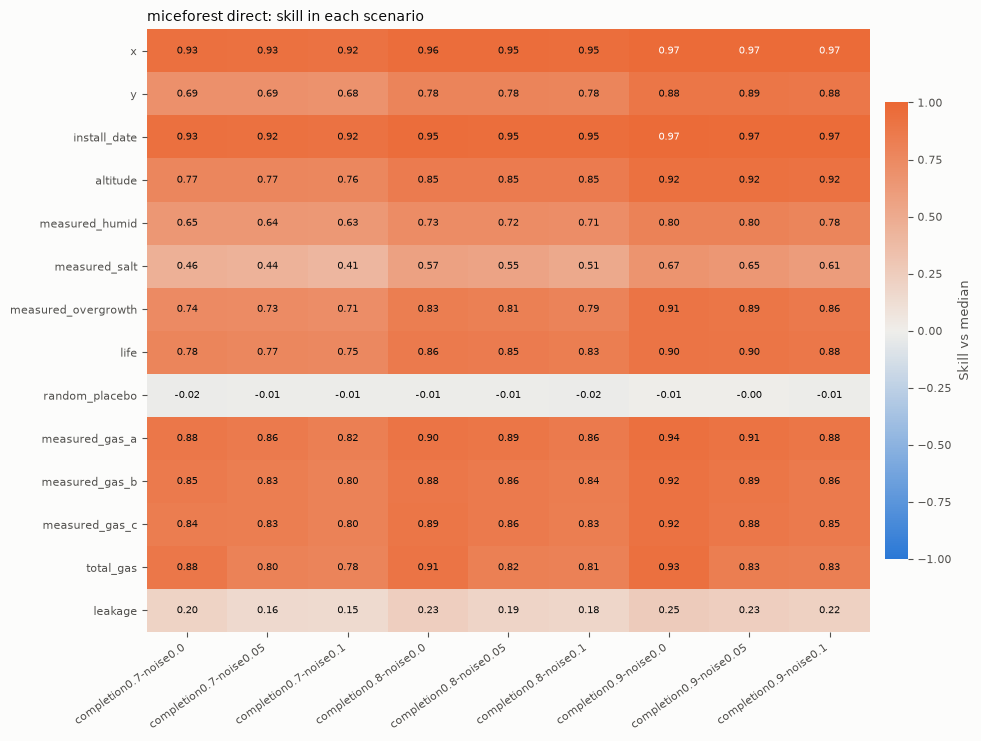

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
miceforest direct,0.9683,0.967,0.9434,0.9842,0.9837,0.9659,0.999,0.997,0.9849


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest direct,45,544.942,26.415,0.846


Tasks: 55 | failed: 0 | with warnings: 0


In [15]:
STUDY.run_model("miceforest direct")
STUDY.show_model("miceforest direct")


### 4.8 miceforest PMM

Predictive mean matching (PMM) does not use a model's prediction as the imputed value. It finds observed rows with similar predictions and copies a real value from one of them. Repeating this gives 20 completed datasets, so the imputed values keep a realistic spread and show their uncertainty. In this section each numeric column is imputed on its own, in the representative scenario.

**Setup:** five candidate donors per cell, using miceforest's default forest of 100 trees. Donor matching compares predictions for rows the model trained on. A model that fits those rows closely finds donors too similar to the prediction, and the draws lose their spread. Each tree of a forest leaves out part of the rows, which limits this effect, so a forest is used here in place of the boosted model of section 4.7.

**Reading the results:** the results table scores the mean of the 20 draws. The purpose of PMM is the spread, which is assessed below and in section 7.1.

In [16]:
STUDY.run_model("miceforest PMM")
STUDY.show_model("miceforest PMM")


Experiments: 70 tasks
7/70 tasks, 4 s
14/70 tasks, 8 s
21/70 tasks, 9 s
28/70 tasks, 12 s
35/70 tasks, 13 s
42/70 tasks, 16 s
49/70 tasks, 19 s
56/70 tasks, 21 s
63/70 tasks, 24 s
70/70 tasks, 24 s


**miceforest PMM · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,2.4030,4.3415,0.9772,0.1769,0.9034,0.5754,0.8925,0.2246
1,y,9.2980,13.9273,0.7702,-0.3424,0.6328,0.1343,0.4747,0.0470
2,install_date,34.1642,62.0037,0.9756,0.0659,0.9005,0.2423,0.6903,0.0162
3,altitude,9.4575,14.3449,0.8790,0.1288,0.7208,0.1223,0.4749,0.0368
4,measured_humid,0.0697,0.0933,0.7983,0.0020,0.5970,0.3327,0.4345,NaN
5,measured_salt,0.1269,0.1672,0.5426,0.0030,0.4009,0.2292,0.3271,NaN
6,measured_overgrowth,0.0848,0.1313,0.8708,0.0028,0.7181,0.3448,0.4567,NaN
7,life,113.7326,160.7372,0.8256,-3.8544,0.6079,0.5924,0.9898,NaN
8,random_placebo,0.2740,0.3234,-0.2371,0.0200,-0.0829,0.0940,0.1397,NaN
9,measured_gas_a,186.8068,303.0906,0.9542,-1.0989,0.8503,0.9515,0.9790,NaN


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,miceforest PMM,70,246.564,33.506,4.001


Tasks: 70 | failed: 0 | with warnings: 0


**Spread of the draws.** The table shows how often the truth falls in the band from the 10th to the 90th percentile of the draws. With 20 draws, this band covers about 72% of cells even when the draws are well calibrated, so 72% is the value to compare with. The spread is not a validated prediction interval.

In [17]:
display(ev.draw_table(STUDY.scored["miceforest PMM"], STUDY.draws["miceforest PMM"], STUDY.config).round(4))


,target,method,n,draws,distinct draws per cell,truth in band,mean band width
0,random_placebo,miceforest PMM,2011,20,19.9160,0.6156,0.6236
1,measured_gas_b,miceforest PMM,2039,20,18.1692,0.9353,831.4783
2,measured_gas_c,miceforest PMM,2049,20,17.7989,0.9151,791.0581
3,measured_gas_a,miceforest PMM,2043,20,18.0847,0.9246,822.0885
4,measured_salt,miceforest PMM,1972,20,19.4878,0.7312,0.3653
5,measured_humid,miceforest PMM,1984,20,19.0509,0.7198,0.1917
6,install_date,miceforest PMM,1973,20,15.4404,0.7719,87.0977
7,x,miceforest PMM,1990,20,7.6503,0.8201,6.0553
8,measured_overgrowth,miceforest PMM,1959,20,13.6274,0.8142,0.2218
9,life,miceforest PMM,1958,20,18.8687,0.7053,298.8655


### 4.9 Joint miceforest PMM

The joint model imputes all incomplete columns together by chained equations, with donor matching. Unlike section 4.8, it fills a row's hidden cells as one process, and it also covers `model_id`.

**Setup:** three passes from the original gaps, producing 20 completed datasets in the representative scenario. The model is small, at 100 rounds of seven-leaf trees with at least 50 rows per leaf, for the reason given in section 4.8. The chain supplies the accuracy that a small model lacks.

**Reading the results:** the results table scores the mean of the draws, or the majority vote for `model_id`. Section 6.6 checks whether completed rows stay consistent.

In [18]:
STUDY.run_model("Joint miceforest PMM")
STUDY.show_model("Joint miceforest PMM")


Experiments: 5 tasks
1/5 tasks, 58 s
2/5 tasks, 58 s
3/5 tasks, 58 s
4/5 tasks, 58 s
5/5 tasks, 59 s


**Joint miceforest PMM · numeric targets · completion0.8-noise0.05**

,target,MAE,RMSE,R2,bias,skill,within tight,within loose,exact
0,x,2.0131,3.8979,0.9816,0.1950,0.9191,0.6452,0.9126,0.2990
1,y,6.7167,12.5214,0.8143,-0.2500,0.7347,0.3020,0.7217,0.1025
2,install_date,27.9083,54.8285,0.9810,0.6422,0.9187,0.3320,0.7714,0.0203
3,altitude,5.9105,12.2182,0.9122,0.0229,0.8255,0.4451,0.7941,0.1666
4,measured_humid,0.0593,0.0850,0.8322,0.0023,0.6575,0.4320,0.5333,NaN
5,measured_salt,0.1117,0.1519,0.6224,0.0012,0.4723,0.2799,0.3960,NaN
6,measured_overgrowth,0.0720,0.1210,0.8901,0.0039,0.7607,0.4391,0.5540,NaN
7,life,75.2642,115.8950,0.9093,-0.2701,0.7405,0.7625,0.9923,NaN
8,random_placebo,0.2629,0.3064,-0.1101,0.0148,-0.0389,0.0950,0.1477,NaN
9,measured_gas_a,154.0965,277.9814,0.9614,-18.1937,0.8765,0.9731,0.9829,NaN


**model_id · completion0.8-noise0.05**

,method,n,accuracy,macro F1,balanced accuracy
0,Joint miceforest PMM,1965,0.9832,0.9821,0.9823


,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,Joint miceforest PMM,5,229.117,59.978,3.855


Tasks: 5 | failed: 0 | with warnings: 5


**Spread of the draws.** This table reads the same way as the one in section 4.8.

In [19]:
display(ev.draw_table(STUDY.scored["Joint miceforest PMM"], STUDY.draws["Joint miceforest PMM"], STUDY.config).round(4))


,target,method,n,draws,distinct draws per cell,truth in band,mean band width,truth among draws
0,x,Joint miceforest PMM,1990,20,7.5070,0.8387,4.7624,NaN
1,y,Joint miceforest PMM,1980,20,12.5939,0.8167,18.0201,NaN
2,install_date,Joint miceforest PMM,1973,20,16.3411,0.7633,66.0677,NaN
3,altitude,Joint miceforest PMM,2011,20,11.3192,0.7976,12.4102,NaN
4,measured_humid,Joint miceforest PMM,1984,20,19.5499,0.7198,0.1627,NaN
5,measured_salt,Joint miceforest PMM,1972,20,19.7272,0.7500,0.3323,NaN
6,measured_overgrowth,Joint miceforest PMM,1959,20,14.1644,0.8504,0.1935,NaN
7,life,Joint miceforest PMM,1958,20,19.5393,0.7451,208.2538,NaN
8,random_placebo,Joint miceforest PMM,2011,20,19.9274,0.6847,0.6973,NaN
9,measured_gas_a,Joint miceforest PMM,2043,20,19.0230,0.9574,761.2935,NaN


## 5. Comparing the models

**The evaluation starts here.** Chapters 5 to 8 need only the setup cell and a finished run. They use saved predictions and fit no model, so they can be repeated quickly after any change to the evaluation code.

The next cell collects all results and shows the overall comparison. Charts show the representative scenario.

,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,1580,1580,1580,0,130


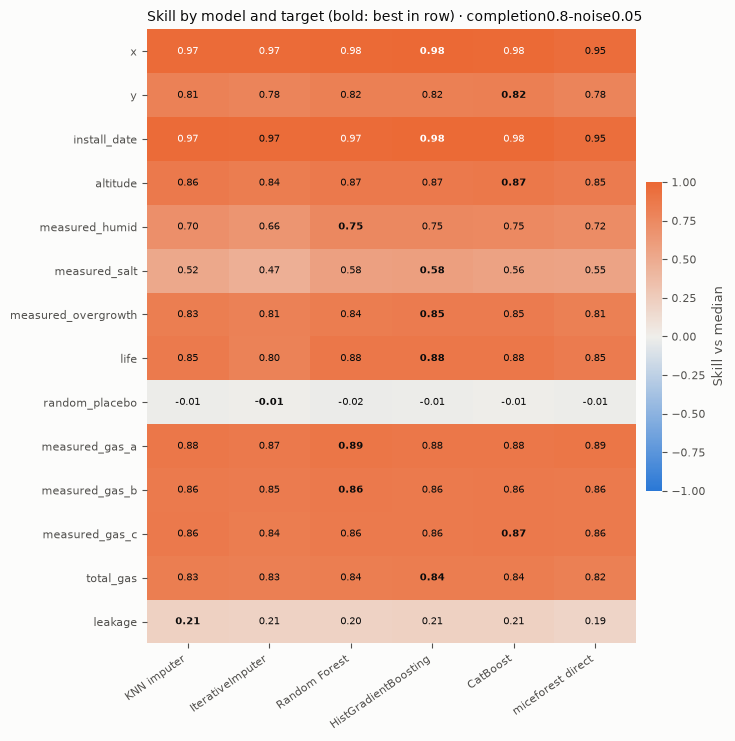

,method,n,accuracy,macro F1,balanced accuracy
0,Mode,1965,0.2809,0.1774,0.2483
1,KNN imputer,1965,0.9781,0.9771,0.9773
2,Random Forest,1965,0.9786,0.9774,0.9763
3,HistGradientBoosting,1965,0.9807,0.9794,0.9794
4,CatBoost,1965,0.9791,0.9778,0.9778
5,miceforest direct,1965,0.9837,0.9827,0.9828


In [20]:
STUDY.finish()
NUMERIC, CATEGORY, PAIRS, GROUPS = STUDY.numeric, STUDY.category, STUDY.pairs, STUDY.groups
SCORED, DRAWS, FIGURES = STUDY.all_scored, STUDY.all_draws, STUDY.figures
display(ev.run_summary(STUDY.log, STUDY.plan))

main_rep = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.scenario.eq(REPRESENTATIVE) & NUMERIC.method.ne("Median")]
skill = main_rep.pivot(index="target", columns="method", values="skill").reindex(list(NUMERIC_TARGETS))
skill = skill[[m for m in NUMERIC_METHODS if m != "Median"]]
fg.plot_heatmap(skill, f"Skill by model and target (bold: best in row) · {REPRESENTATIVE}", FIGURES, "skill_by_model",
                "Skill vs median", center=0.0, limit=1.0, marks=skill.eq(skill.max(axis=1), axis=0).to_numpy())
labels = CATEGORY[CATEGORY.experiment.eq("main") & CATEGORY.scenario.eq(REPRESENTATIVE)]
display(labels.set_index("method").reindex(CATEGORY_METHODS).reset_index()[
    ["method", "n", "accuracy", "macro F1", "balanced accuracy"]].round(4))


**Size of the differences.** The next cell compares methods on the same cells. The intervals resample rows for fitted models. They do not include refitting or the randomness of the dataset itself, so they describe a gap on these cells and do not prove it in general. A gap can be clear and still too small to matter, so the last column shows it relative to the better method's error.

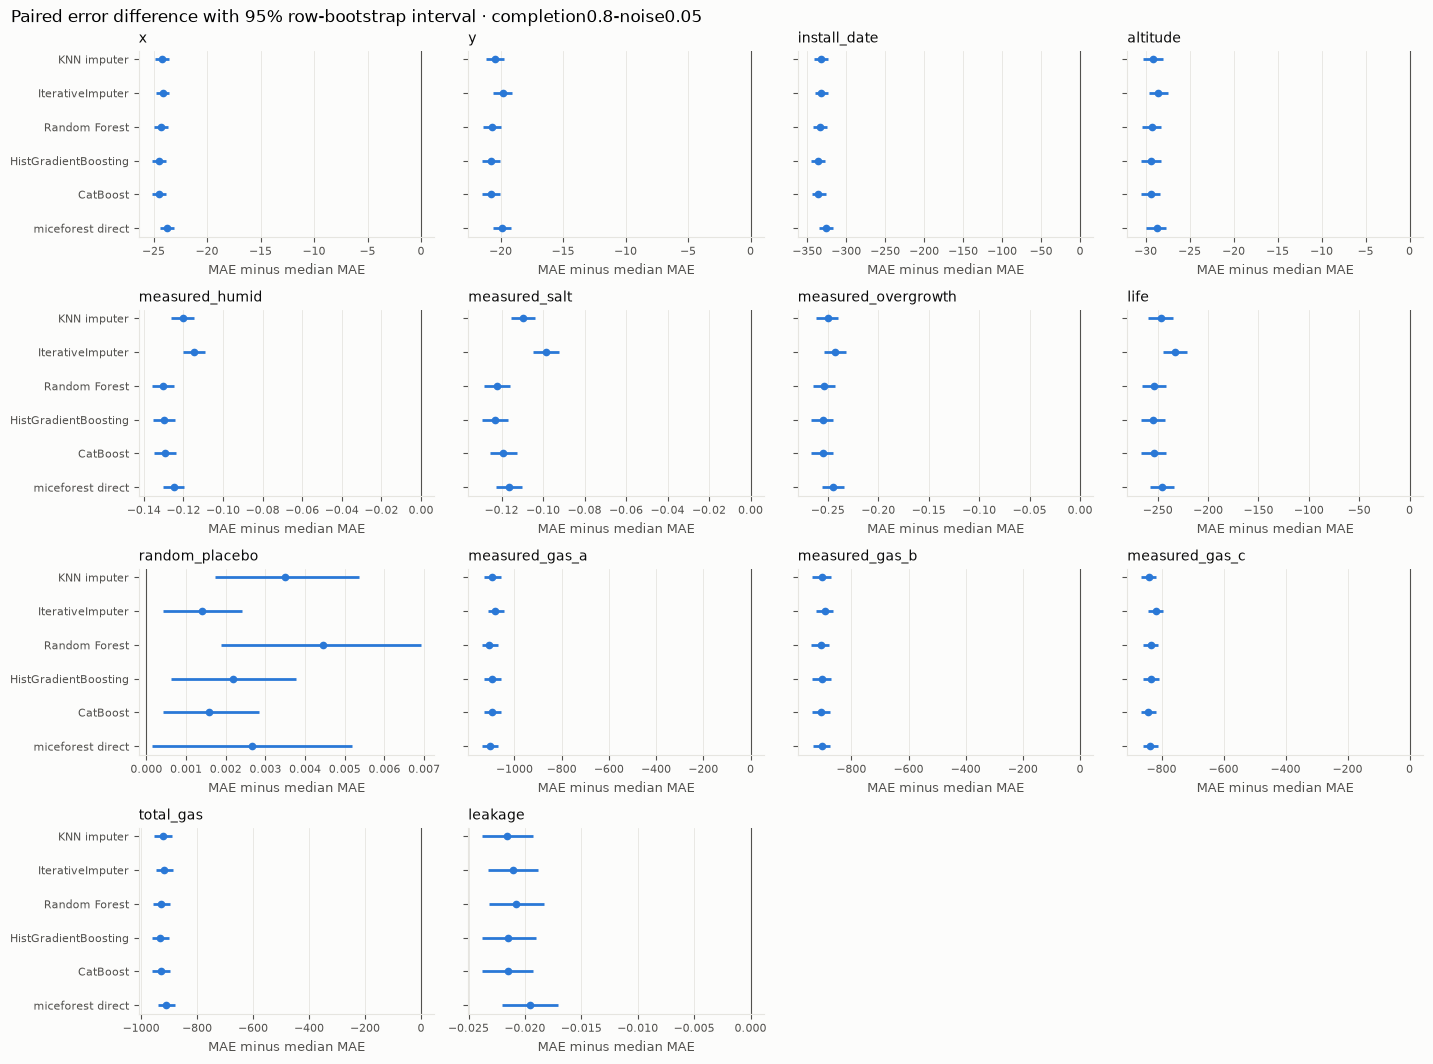

,target,first,second,metric,difference,low,high,relative gap
0,x,HistGradientBoosting,CatBoost,MAE,0.03116,-0.00503,0.06834,0.08042
1,y,CatBoost,HistGradientBoosting,MAE,0.05404,-0.07629,0.17932,0.01193
2,install_date,HistGradientBoosting,CatBoost,MAE,0.34668,-0.18210,0.87082,0.04831
3,altitude,CatBoost,HistGradientBoosting,MAE,0.07757,-0.04525,0.18849,0.01749
4,measured_humid,Random Forest,HistGradientBoosting,MAE,0.00036,-0.00093,0.00163,0.00834
5,measured_salt,HistGradientBoosting,Random Forest,MAE,0.00068,-0.00131,0.00285,0.00762
6,measured_overgrowth,HistGradientBoosting,CatBoost,MAE,0.00005,-0.00162,0.00162,0.00107
7,life,HistGradientBoosting,CatBoost,MAE,0.48601,-1.09268,1.99654,0.01375
8,random_placebo,IterativeImputer,CatBoost,MAE,0.00018,-0.00027,0.00064,0.00069
9,measured_gas_a,Random Forest,miceforest direct,MAE,1.86905,-6.47689,10.20114,0.01323


In [21]:
fg.plot_paired(PAIRS, REPRESENTATIVE, FIGURES)
closest = PAIRS[PAIRS.scenario.eq(REPRESENTATIVE) & PAIRS.comparison.eq("best two")].copy()
closest["relative gap"] = closest["second error"] / closest["first error"].where(closest["first error"] > 0) - 1
closest = closest.set_index("target").reindex(list(TARGETS)).reset_index()
display(closest[["target", "first", "second", "metric", "difference", "low", "high", "relative gap"]].round(5))


**Predictions outside the valid range.** The table shows the share of raw predictions outside the range a column allows. A method can show low error and still produce impossible values. Scoring uses the limited values.

In [22]:
ranges = ev.range_table(SCORED).pivot(index="target", columns="method", values="outside valid range")
display(ranges.reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)].round(4))


method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct
target,,,,,,,
x,0.0,0.0089,0.0000,0.0078,0.0090,0.0084,0.0010
y,0.0,0.0043,0.0000,0.0085,0.0059,0.0070,0.0001
install_date,0.0,0.0010,0.0000,0.0003,0.0006,0.0003,0.0000
altitude,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
measured_humid,0.0,0.0022,0.0003,0.0013,0.0023,0.0038,0.0002
measured_salt,0.0,0.0202,0.0031,0.0134,0.0191,0.0209,0.0001
measured_overgrowth,0.0,0.1827,0.0000,0.1521,0.1572,0.1563,0.0972
life,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
random_placebo,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


**Change from the earlier study.** The first table compares mean skill with the earlier study on the same cells. The second shows the effect of the ridge base, using the error ratio from the selection data, where lower is better. Both are skipped in a quick check.

In [23]:
progress = rel.progress_table(NUMERIC, ROOT, STUDY.config)
if progress is not None:
    display(progress.round(3))
    display(rel.base_table(ROOT).round(4))


,earlier study,this run,change
method,,,
HistGradientBoosting,0.755,0.796,0.041
CatBoost,0.750,0.795,0.045
Random Forest,0.754,0.794,0.040
KNN imputer,0.581,0.781,0.199
miceforest direct,0.700,0.775,0.076
IterativeImputer,0.680,0.760,0.080
Joint miceforest PMM,0.718,0.737,0.019
miceforest PMM,0.701,0.683,-0.018


,method,no base,straight-line base,second-order base
0,KNN imputer,0.5020,0.3757,0.3602
1,Random Forest,0.3554,0.3398,0.3321
2,HistGradientBoosting,0.3477,0.3327,0.3272
3,CatBoost,0.3476,0.3343,0.3306


## 6. Relationships and failure

Models receive no relationships, so anything they use was learned from the data. The generator's definitions are used here only to check the results.

### 6.1 Negative control

`random_placebo` is unrelated to every other column. A clear gain over the median would mean a method has found structure that does not exist. Falling behind the median means the method is fitting noise. The last table checks the same control from the other side: importance given to `random_placebo` as a predictor should stay near zero.

In [24]:
control = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.target.eq("random_placebo")]
display(control.pivot(index="method", columns="scenario", values="skill").reindex(NUMERIC_METHODS).round(4))
comparisons = PAIRS[PAIRS.target.eq("random_placebo") & PAIRS.comparison.eq("versus baseline")]
print("Scenarios where each method is clearly better or worse than the median:")
display(comparisons.assign(better=comparisons.high.lt(0), worse=comparisons.low.gt(0)).groupby("second")[["better", "worse"]].sum())
importance = STUDY.all_importance
placebo_use = importance[importance.predictor.eq("random_placebo") & importance.target.ne("random_placebo")]
display(placebo_use.groupby(["method", "scenario"]).importance.agg(["mean", "max"]).round(4))


scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
method,,,,,,,,,
Median,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
KNN imputer,-0.0109,-0.0124,-0.0141,-0.0142,-0.0138,-0.0143,-0.0056,-0.0021,-0.0026
IterativeImputer,-0.0038,-0.0033,-0.0022,-0.0056,-0.0056,-0.0052,-0.0026,-0.0010,-0.0003
Random Forest,-0.0146,-0.0121,-0.0155,-0.0212,-0.0175,-0.0135,-0.0044,-0.0054,-0.0046
HistGradientBoosting,-0.0071,-0.0068,-0.0066,-0.0099,-0.0086,-0.0057,0.0004,-0.0014,-0.0028
CatBoost,-0.0053,-0.0049,-0.0045,-0.0059,-0.0063,-0.0059,-0.0022,-0.0015,-0.0006
miceforest direct,-0.0192,-0.0132,-0.0145,-0.0141,-0.0105,-0.0182,-0.0071,-0.0035,-0.0118


Scenarios where each method is clearly better or worse than the median:


,better,worse
second,,
CatBoost,0,4
HistGradientBoosting,0,5
IterativeImputer,0,4
KNN imputer,0,6
Random Forest,0,6
miceforest direct,0,6


mean     max
method        scenario                               
CatBoost      completion0.8-noise0.0  -0.0001  0.0017
              completion0.8-noise0.05 -0.0000  0.0033
              completion0.8-noise0.1  -0.0001  0.0026
Random Forest completion0.8-noise0.0  -0.0003  0.0019
              completion0.8-noise0.05 -0.0002  0.0033
              completion0.8-noise0.1   0.0001  0.0022

### 6.2 Recovering known relationships

Each row takes one relationship from the generator and keeps only the hidden cells whose defining inputs are all visible, so a low error means the model has learned that relationship. Values are MAE.

`Formula` applies the generator's definition to the visible inputs. It is a reference that no model has. With noise, a model can beat it, because other columns help to average out errors in the inputs. The `leakage` formula takes the middle of the values the generator allows, which is valid only for exact gases.

The last table shows how much of each column the other true columns could explain. This reference uses the complete truth, so it marks what the data allows rather than what a model could reach. `leakage` stays low even there, and `x` and `install_date` are near copies of each other because assets were installed in grid order.

In [25]:
for scenario in (NOISE_FREE, REPRESENTATIVE, HIGH_NOISE):
    display(Markdown(f"**{scenario}**"))
    display(rel.relation_matrix(STUDY.relations, scenario).round(3))
display(rel.recoverable_table(STUDY.truth[REPRESENTATIVE], NUMERIC, STUDY.config).round(3))


**completion0.8-noise0.0**

,method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,Formula
relation,n,,,,,,,,
altitude from x and y,1308,34.024,0.184,0.217,0.094,0.019,0.008,0.896,0.000
x from altitude and y,1299,24.711,0.366,0.410,0.256,0.091,0.084,1.027,0.000
y from altitude and x,1278,25.280,0.244,0.345,0.104,0.010,0.009,1.250,0.000
total_gas from gas readings,1030,1109.235,48.593,48.364,25.998,16.304,13.659,54.231,0.000
gas a from total and other readings,1018,1248.808,42.027,38.839,24.955,17.777,17.297,69.645,0.000
overgrowth from humidity and salt,1244,0.307,0.019,0.028,0.008,0.008,0.007,0.015,0.000
life from all its inputs,537,294.559,19.948,35.008,12.854,10.804,11.168,25.566,0.000
"leakage from gases, date and model",608,0.097,0.074,0.074,0.073,0.074,0.074,0.076,0.065


**completion0.8-noise0.05**

,method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,Formula
relation,n,,,,,,,,
altitude from x and y,1308,34.024,0.164,0.203,0.106,0.024,0.011,0.922,0.000
x from altitude and y,1299,24.711,0.399,0.418,0.312,0.120,0.117,1.108,0.000
y from altitude and x,1278,25.280,0.234,0.350,0.107,0.023,0.019,1.276,0.000
total_gas from gas readings,1030,1109.235,180.946,183.976,177.136,174.805,178.060,191.284,387.321
gas a from total and other readings,1018,1251.182,120.922,132.953,112.081,109.955,112.996,112.058,322.255
overgrowth from humidity and salt,1244,0.307,0.024,0.031,0.017,0.017,0.017,0.020,0.015
life from all its inputs,537,294.559,23.387,36.866,17.610,15.198,14.915,26.468,8.484
"leakage from gases, date and model",608,0.097,0.078,0.078,0.079,0.078,0.078,0.080,NaN


**completion0.8-noise0.1**

,method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct,Formula
relation,n,,,,,,,,
altitude from x and y,1308,34.024,0.169,0.206,0.104,0.028,0.020,0.946,0.000
x from altitude and y,1299,24.711,0.422,0.419,0.342,0.147,0.135,1.145,0.000
y from altitude and x,1278,25.280,0.232,0.353,0.112,0.029,0.020,1.308,0.000
total_gas from gas readings,1030,1109.235,200.424,204.696,196.423,194.833,194.308,210.546,774.642
gas a from total and other readings,1018,1251.807,144.555,161.761,140.581,130.258,124.805,155.406,644.510
overgrowth from humidity and salt,1244,0.307,0.032,0.039,0.027,0.027,0.027,0.030,0.030
life from all its inputs,537,294.559,28.226,40.920,24.049,21.850,22.086,30.102,16.969
"leakage from gases, date and model",608,0.097,0.080,0.080,0.080,0.080,0.080,0.081,NaN


,target,R2 from all other true columns,"best R2, representative scenario","best R2, easiest scenario"
0,x,1.000,0.996,0.999
1,y,0.999,0.832,0.923
2,install_date,1.000,0.996,0.999
3,altitude,1.000,0.920,0.965
4,measured_humid,0.954,0.878,0.932
5,measured_salt,0.894,0.691,0.808
6,measured_overgrowth,0.999,0.926,0.977
7,life,0.995,0.953,0.990
8,random_placebo,-0.104,-0.012,-0.001
9,measured_gas_a,0.999,0.961,0.994


### 6.3 Columns the models relied on

A chain covers every column at once, so a column's influence on one target cannot be read from it. This section therefore uses single-target forest and CatBoost models. Each predictor is shuffled in held-out rows, and the added error is measured against observed labels, so truth is not involved. A value of 1 means the shuffle cost as much as replacing the model with a constant guess. Bold values mark links in the generator's definition.

The table after the charts scores this against the generator. A column counts as relied on when its importance is above 0.02. `ranking score` is the chance that a direct link ranks above a pair without one. Columns two steps apart are related through a third column, such as `x` and `total_gas` through age.

Columns that carry the same information share importance, so a low value on a linked column does not prove that the model missed it. Some links are also weak by design. Values come from one fold.

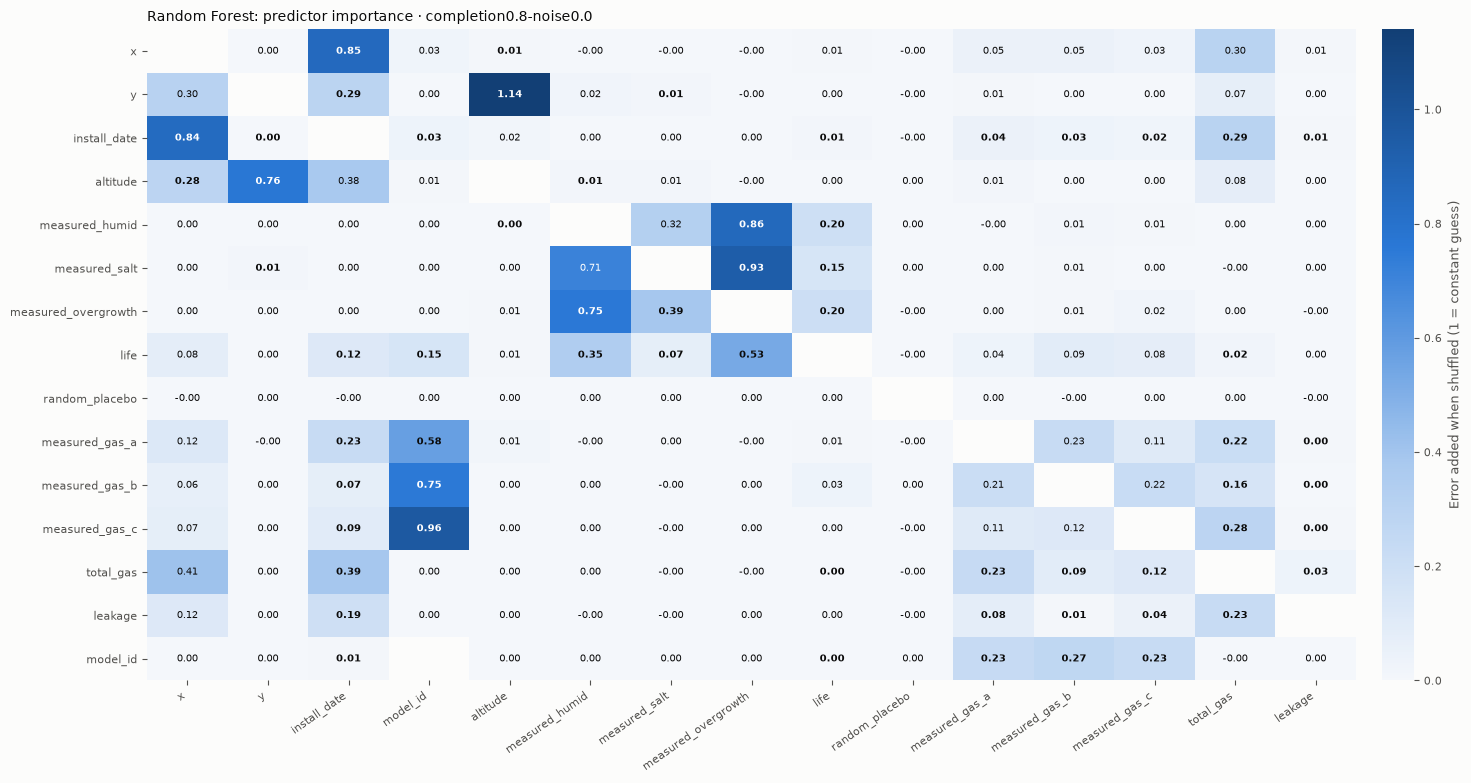

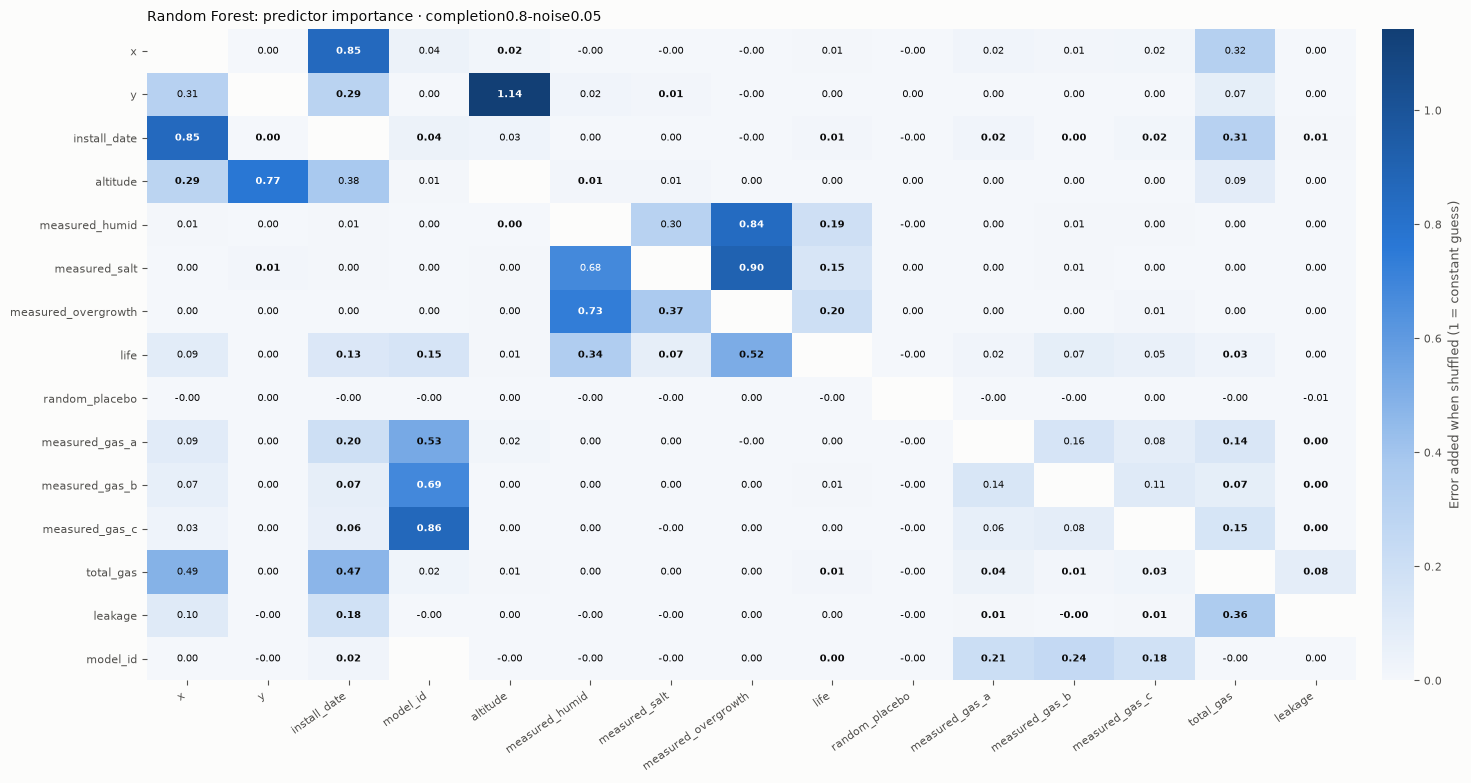

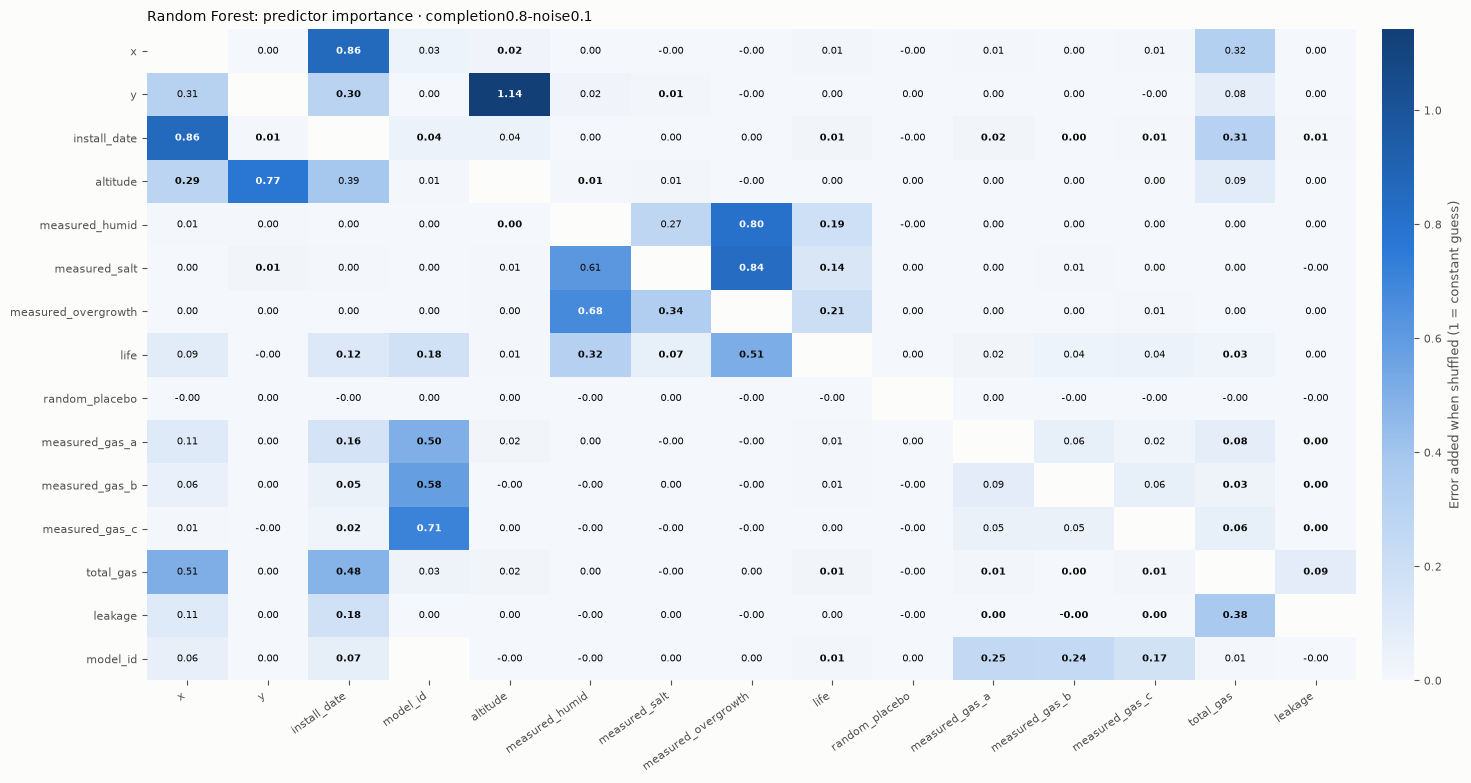

,method,scenario,direct links,ranking score,direct links found,relied on: direct,relied on: two steps,relied on: unrelated
0,Random Forest,completion0.8-noise0.0,60,0.862,0.733,0.611,0.375,0.014
1,Random Forest,completion0.8-noise0.05,60,0.847,0.667,0.606,0.379,0.015
2,Random Forest,completion0.8-noise0.1,60,0.839,0.650,0.619,0.365,0.016
3,CatBoost,completion0.8-noise0.0,60,0.851,0.817,0.598,0.366,0.037
4,CatBoost,completion0.8-noise0.05,60,0.839,0.767,0.597,0.364,0.039
5,CatBoost,completion0.8-noise0.1,60,0.816,0.717,0.573,0.387,0.040


Direct links below the threshold, Random Forest, no noise:


,target,predictor,importance
0,life,total_gas,0.0190
1,measured_salt,y,0.0123
2,y,measured_salt,0.0113
3,altitude,measured_humid,0.0102
4,install_date,life,0.0089
5,x,altitude,0.0085
6,model_id,install_date,0.0079
7,install_date,leakage,0.0072
8,leakage,measured_gas_b,0.0064
9,measured_gas_c,leakage,0.0049


In [26]:
for scenario in (NOISE_FREE, REPRESENTATIVE, HIGH_NOISE):
    matrix = ev.importance_matrix(importance, scenario, "Random Forest")
    fg.plot_importance(matrix, f"Random Forest: predictor importance · {scenario}", FIGURES, f"importance_{scenario}")
display(STUDY.links.round(3))
print("Direct links below the threshold, Random Forest, no noise:")
display(rel.missed_links(importance, NOISE_FREE, "Random Forest").round(4))


### 6.4 Correlation between columns

The table compares correlations in completed data with correlations in the truth, across all 91 pairs of numeric columns. Only rows with an imputed cell in the pair are used, because observed cells would hide any change. A gap of 0 means the correlation is unchanged. Pearson measures straight-line association and Spearman measures rank association. Neither shows thresholds or interactions, which section 6.2 covers.

In [27]:
display(STUDY.correlations.round(4))


,method,mean Pearson gap,largest Pearson gap,mean Spearman gap,largest gap pair
0,HistGradientBoosting,0.0097,0.0631,0.0147,total_gas ~ leakage
1,Random Forest,0.0097,0.0570,0.0126,total_gas ~ leakage
2,CatBoost,0.0098,0.0605,0.0156,total_gas ~ leakage
3,miceforest direct,0.0107,0.0445,0.0134,total_gas ~ leakage
4,KNN imputer,0.0109,0.0575,0.0154,total_gas ~ leakage
5,IterativeImputer,0.0118,0.0646,0.0190,y ~ total_gas
6,Joint miceforest PMM (per draw),0.0158,0.0855,0.0215,measured_humid ~ measured_salt
7,Median,0.2141,1.0001,0.2200,x ~ install_date


### 6.5 Accuracy when related columns are hidden

Hidden cells are grouped by which related columns were visible in the same row, using measured data only. When a model has learned a relationship, skill drops as the columns it depends on are hidden too.

The chart and first table use each target's most important related columns. The heatmap uses all columns linked to the target in the generator's definition, grouped by the share that were visible.

Method shown below, the highest mean skill across targets: HistGradientBoosting


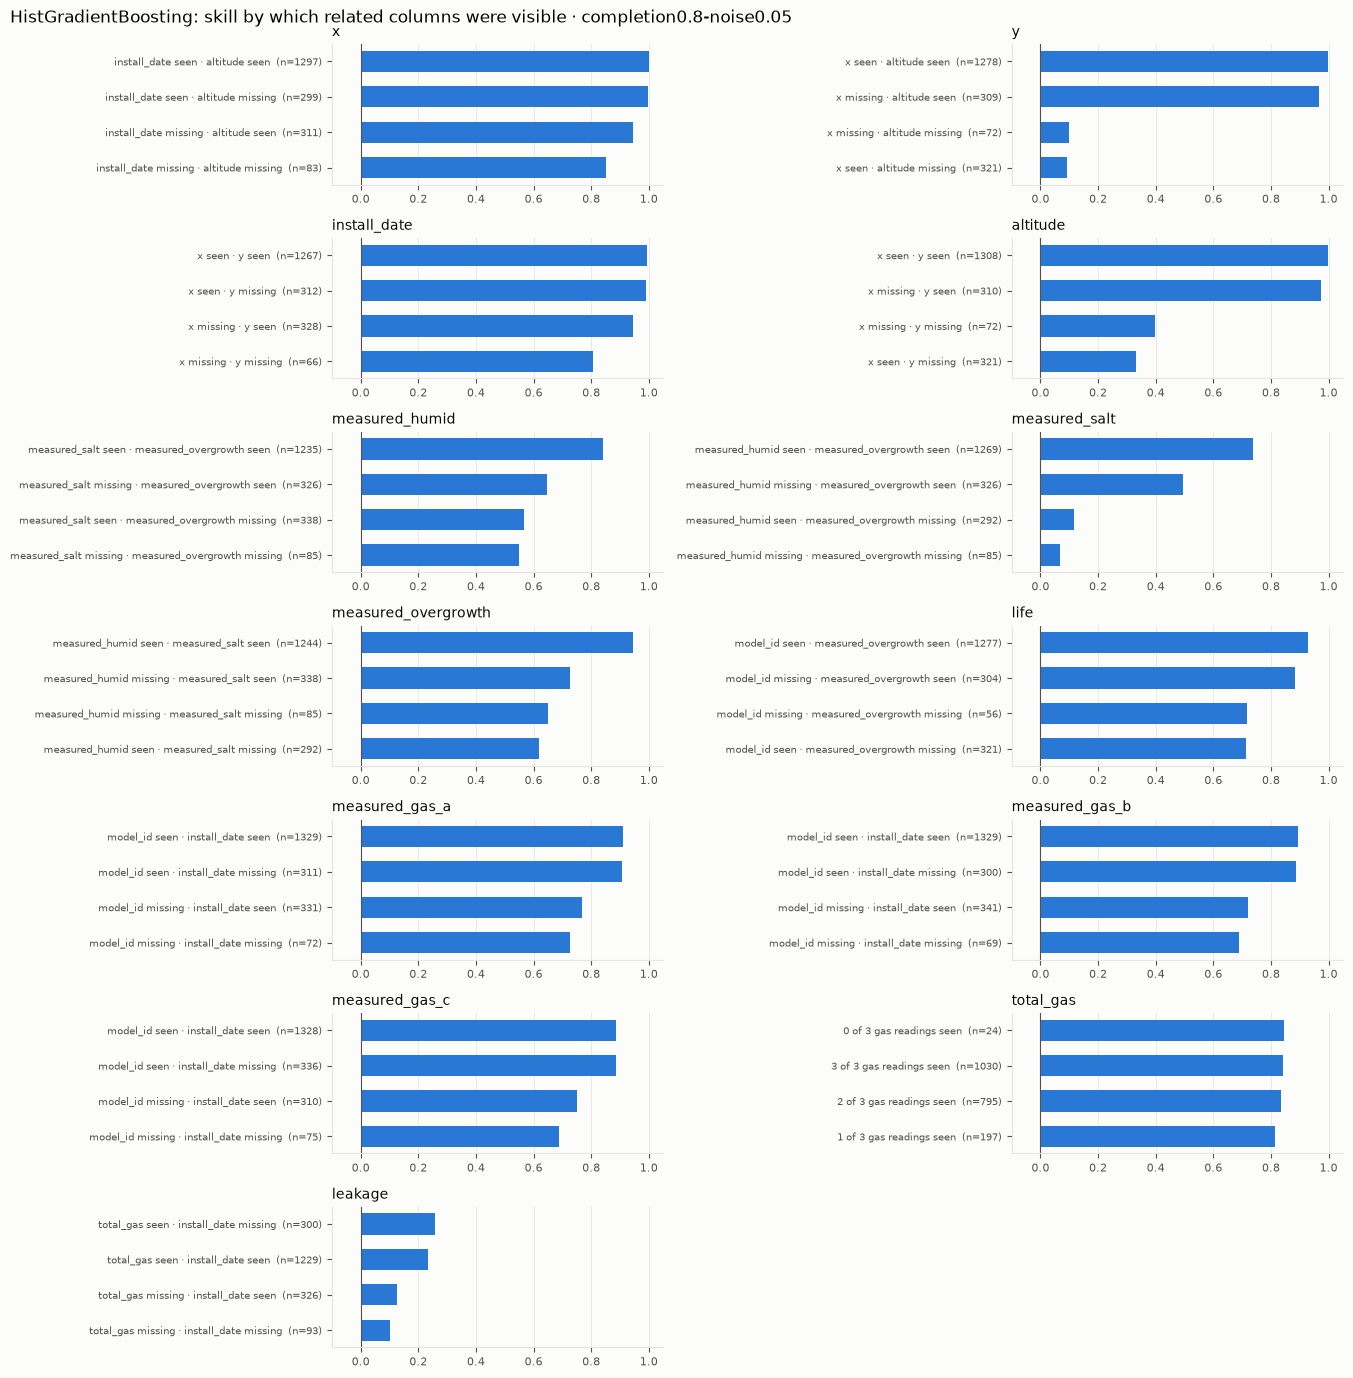

method                                                                         CatBoost  HistGradientBoosting  IterativeImputer  KNN imputer  Random Forest  miceforest direct
target              group                                                n                                                                                                    
altitude            x missing · y missing                                72       0.397                 0.398             0.297        0.375          0.409              0.387
                    x missing · y seen                                   310      0.970                 0.972             0.959        0.963          0.965              0.948
                    x seen · y missing                                   321      0.347                 0.331             0.237        0.329          0.337              0.350
                    x seen · y seen                                      1308     1.000                 0.999             0.994        0.995          0.997              0.973
install_date        x missing · y missing                                66       0.782                 0.806             0.764        0.799          0.800              0.790
                    x missing · y seen                                   328      0.942                 0.946             0.926        0.925          0.916              0.814
                    x seen · y missing                                   312      0.992                 0.991             0.980        0.981          0.989              0.982
                    x seen · y seen                                      1267     0.994                 0.993             0.984        0.985          0.991              0.983
leakage             total_gas missing · install_date missing             93       0.101                 0.103             0.063        0.065          0.118              0.080
                    total_gas missing · install_date seen                326      0.119                 0.125             0.114        0.132          0.098              0.065
                    total_gas seen · install_date missing                300      0.256                 0.258             0.259        0.260          0.266              0.229
                    total_gas seen · install_date seen                   1229     0.235                 0.232             0.233        0.235          0.226              0.228
life                model_id missing · measured_overgrowth missing       56       0.700                 0.718             0.655        0.685          0.717              0.669
                    model_id missing · measured_overgrowth seen          304      0.890                 0.884             0.781        0.870          0.895              0.865
                    model_id seen · measured_overgrowth missing          321      0.706                 0.712             0.639        0.682          0.709              0.694
                    model_id seen · measured_overgrowth seen             1277     0.926                 0.928             0.860        0.900          0.923              0.891
measured_gas_a      model_id missing · install_date missing              72       0.695                 0.728             0.680        0.706          0.756              0.800
                    model_id missing · install_date seen                 331      0.780                 0.769             0.706        0.790          0.819              0.806
                    model_id seen · install_date missing                 311      0.903                 0.908             0.907        0.902          0.905              0.901
                    model_id seen · install_date seen                    1329     0.908                 0.909             0.909        0.905          0.907              0.906
measured_gas_b      model_id missing · install_date missing              69       0.654                 0.690             0.641        0.766          

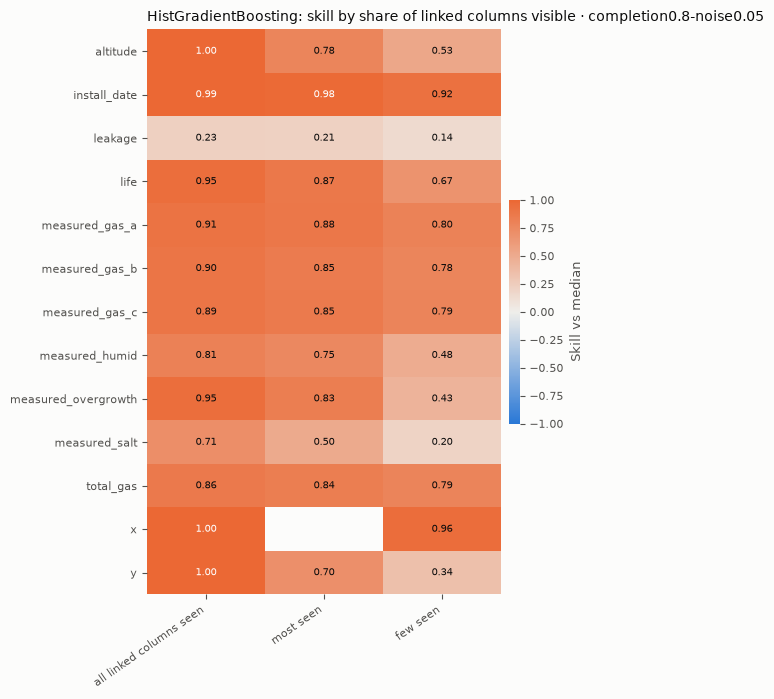

In [28]:
best_overall = main_rep[main_rep.target.ne("random_placebo")].groupby("method").skill.mean().idxmax()
print("Method shown below, the highest mean skill across targets:", best_overall)
fg.plot_groups(GROUPS, REPRESENTATIVE, best_overall, FIGURES)
wide = GROUPS[GROUPS.scenario.eq(REPRESENTATIVE) & GROUPS.target.ne("random_placebo")
              & ~GROUPS.method.isin(["Median", "Mode"])]
display(wide.pivot_table(index=["target", "group", "n"], columns="method", values="skill").round(3))
seen = STUDY.visibility[STUDY.visibility.method.eq(best_overall)].pivot(index="target", columns="level", values="skill")
seen = seen.reindex(columns=["all linked columns seen", "most seen", "few seen"])
fg.plot_heatmap(seen, f"{best_overall}: skill by share of linked columns visible · {REPRESENTATIVE}", FIGURES,
                "skill_by_linked_columns", "Skill vs median", center=0.0, limit=1.0)


### 6.6 Consistency of completed rows

Three generator definitions can be checked directly on completed rows. A method that fills each cell on its own can leave a row that contradicts itself even when each cell is close to the truth. The last column gives the same residual on rows with nothing imputed, which is the level that measurement noise alone produces. A single joint draw is noisier than a point prediction by design, so the mean of the draws is shown beside it.

In [29]:
display(ev.coherence_table(SCORED, DRAWS, STUDY.measured[REPRESENTATIVE], STUDY.config).round(4))


,relation,method,rows,mean residual,residual in fully observed rows
0,altitude = x + y + 100,Median,4897,27.4631,0.0000
1,altitude = x + y + 100,KNN imputer,4897,0.2530,0.0000
2,altitude = x + y + 100,IterativeImputer,4897,0.3053,0.0000
3,altitude = x + y + 100,Random Forest,4897,0.1785,0.0000
4,altitude = x + y + 100,HistGradientBoosting,4897,0.0694,0.0000
5,altitude = x + y + 100,CatBoost,4897,0.0615,0.0000
6,altitude = x + y + 100,miceforest direct,4897,1.6220,0.0000
7,altitude = x + y + 100,Joint miceforest PMM (mean of draws),4897,2.4952,0.0000
8,altitude = x + y + 100,Joint miceforest PMM (one draw),4897,5.0970,0.0000
9,"overgrowth = max(2 humid - salt, 0)",Median,4789,0.2362,0.0174


### 6.7 Noise and completeness

The heatmap shows the best skill reached in each scenario. The two effect charts then measure each control on identical cells, so nothing else differs between the two sides. For completeness, the cells are those hidden at both levels, so only the visible information around them changes. Bold values have a 95% row-bootstrap interval that excludes zero.

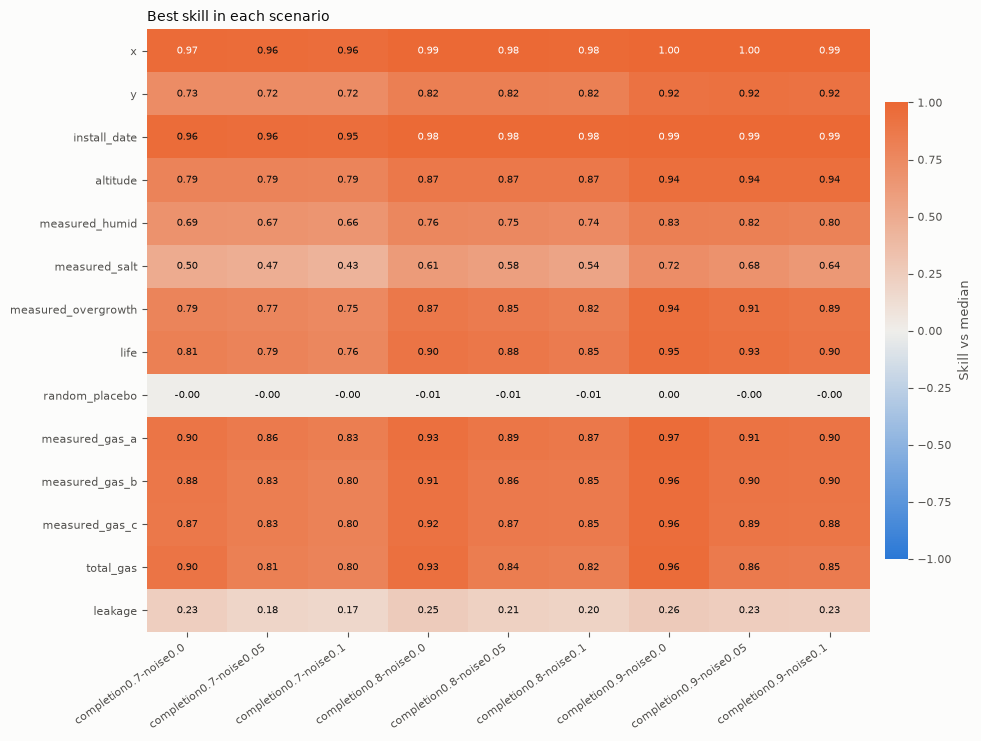

scenario,completion0.7-noise0.0,completion0.7-noise0.05,completion0.7-noise0.1,completion0.8-noise0.0,completion0.8-noise0.05,completion0.8-noise0.1,completion0.9-noise0.0,completion0.9-noise0.05,completion0.9-noise0.1
best model_id accuracy,0.9693,0.9673,0.9441,0.9842,0.9837,0.9659,0.999,0.999,0.9869


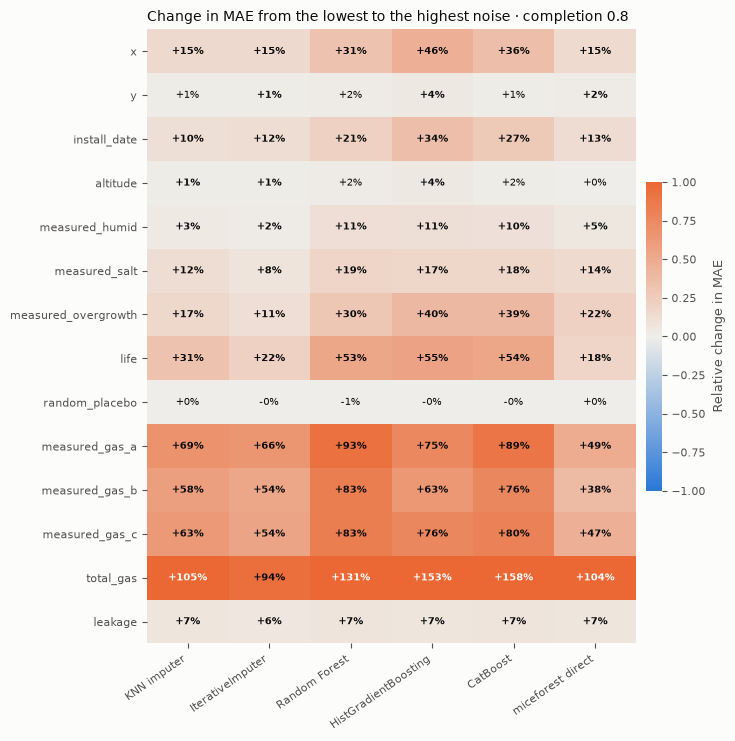

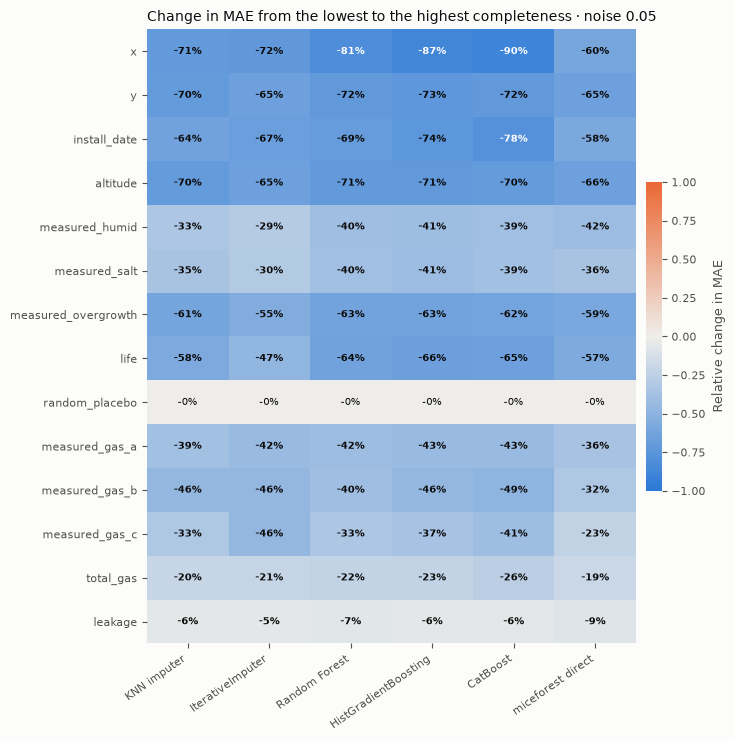

In [30]:
best_skill = NUMERIC[NUMERIC.experiment.eq("main") & NUMERIC.method.ne("Median")].groupby(
    ["target", "scenario"]).skill.max().unstack().reindex(list(NUMERIC_TARGETS))
fg.plot_heatmap(best_skill, "Best skill in each scenario", FIGURES, "best_skill_by_scenario", "Skill vs median",
                center=0.0, limit=1.0)
accuracy = CATEGORY[CATEGORY.experiment.eq("main") & CATEGORY.method.ne("Mode")].groupby("scenario").accuracy.max()
display(accuracy.rename("best model_id accuracy").to_frame().T.round(4))

completion_level, noise_level = 0.8, 0.05
noise_matrix, noise_marks = ev.effect_matrix(STUDY.effects, "noise", "held completion", completion_level)
fg.plot_heatmap(noise_matrix, f"Change in MAE from the lowest to the highest noise · completion {completion_level}",
                FIGURES, "noise_effect", "Relative change in MAE", center=0.0, limit=1.0, marks=noise_marks, fmt="{:+.0%}")
complete_matrix, complete_marks = ev.effect_matrix(STUDY.effects, "completeness", "held noise", noise_level)
fg.plot_heatmap(complete_matrix, f"Change in MAE from the lowest to the highest completeness · noise {noise_level}",
                FIGURES, "completeness_effect", "Relative change in MAE", center=0.0, limit=1.0, marks=complete_marks,
                fmt="{:+.0%}")


### 6.8 Removing predictor blocks

Each block of columns is removed according to what it measures, and the models are refitted. Values show the relative change in MAE, so a positive value means the block was helping. Empty cells are targets inside the removed block.

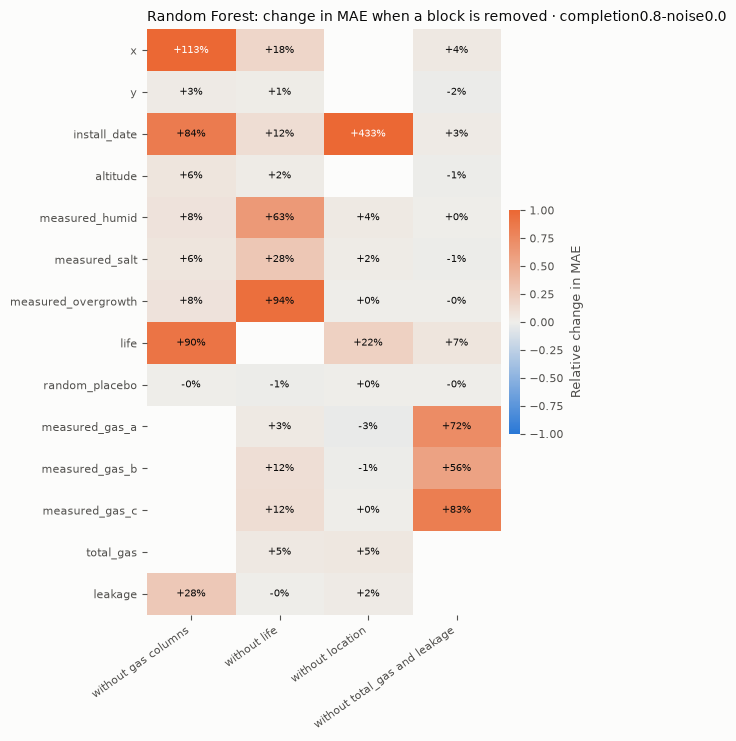

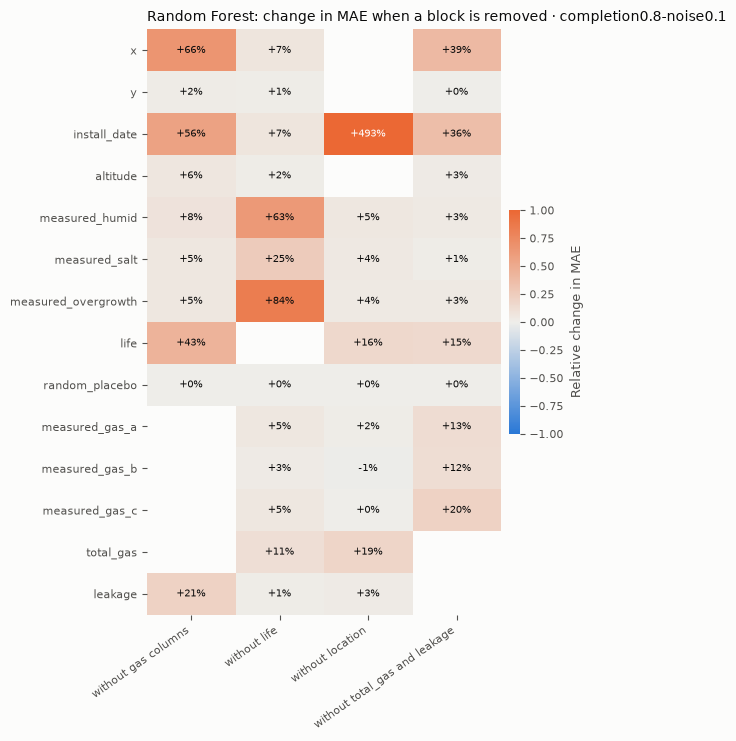

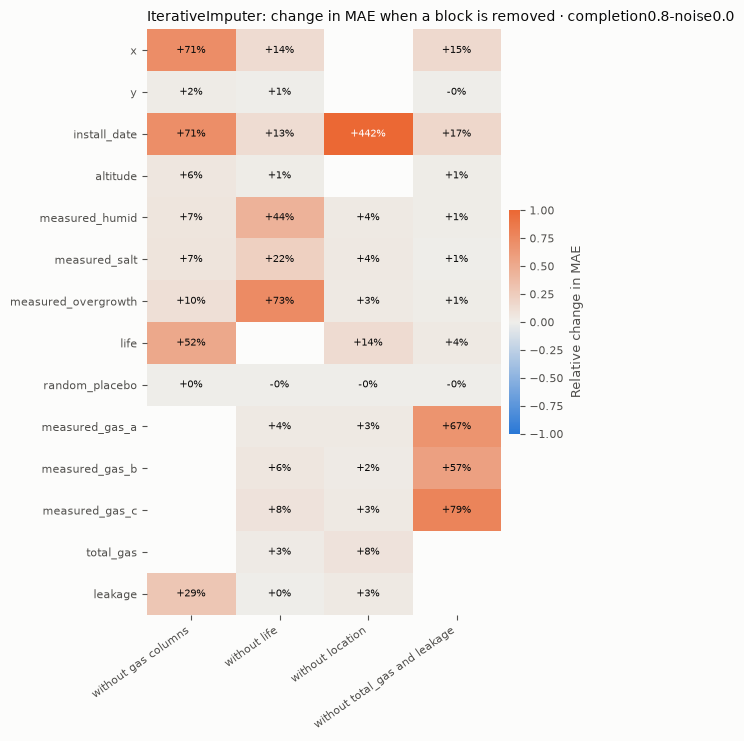

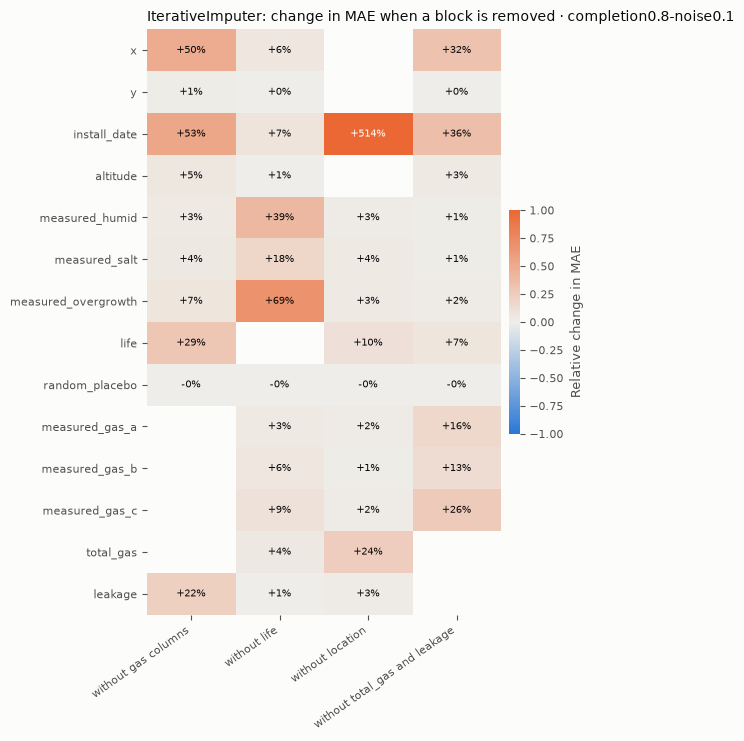

model_id accuracy without each block:


variant                                without gas columns  without life  without location  without total_gas and leakage
scenario                method                                                                                           
completion0.8-noise0.0  CatBoost                    0.7618        0.9796            0.9837                         0.9852
                        KNN imputer                 0.6443        0.9751            0.9766                         0.9807
                        Random Forest               0.7557        0.9822            0.9847                         0.9852
completion0.8-noise0.05 CatBoost                    0.7639        0.9766            0.9817                         0.9807
                        KNN imputer                 0.6478        0.9695            0.9746                         0.9751
                        Random Forest               0.7420        0.9791            0.9812                         0.9796
completion0.8-noise0.1  CatBoost                    0.7593        0.9532            0.9593                         0.9639
                        KNN imputer                 0.6519        0.9328            0.9415                         0.9486
                        Random Forest               0.7522        0.9522            0.9573                         0.9603

In [31]:
for method in ("Random Forest", "IterativeImputer"):
    for scenario in (NOISE_FREE, HIGH_NOISE):
        block = STUDY.ablation[STUDY.ablation.method.eq(method) & STUDY.ablation.scenario.eq(scenario)]
        matrix = block.pivot(index="target", columns="variant", values="relative change").reindex(list(NUMERIC_TARGETS))
        slug = method.replace(" ", "_")
        fg.plot_heatmap(matrix, f"{method}: change in MAE when a block is removed · {scenario}", FIGURES,
                        f"ablation_{slug}_{scenario}", "Relative change in MAE", center=0.0, limit=1.0, fmt="{:+.0%}")
print("model_id accuracy without each block:")
display(STUDY.ablation_labels.pivot_table(index=["scenario", "method"], columns="variant", values="without").round(4))


### 6.9 Where errors concentrate in the value range

Cells are grouped by their true value after the fact, so this table explains errors and cannot be used as a rule when filling data. Models that pull predictions towards the centre show large errors and opposite biases in the outer bands. `measured_overgrowth` is split into true zeros and positive values.

In [32]:
tails = ev.tail_table(SCORED, STUDY.config)
display(tails.pivot_table(index=["target", "band"], columns="method", values="MAE", sort=False)[list(NUMERIC_METHODS)].round(4))


method                                       Median  KNN imputer  IterativeImputer  Random Forest  HistGradientBoosting  CatBoost  miceforest direct
target              band                                                                                                                            
measured_humid      lowest 10%               0.2848       0.0929            0.0939         0.0799                0.0743    0.0764             0.0807
                    middle 80%               0.1307       0.0469            0.0529         0.0381                0.0387    0.0391             0.0433
                    highest 10%              0.3986       0.0580            0.0656         0.0432                0.0475    0.0459             0.0541
measured_salt       lowest 10%               0.3659       0.1334            0.1468         0.1053                0.1081    0.1115             0.1283
                    middle 80%               0.1653       0.0895            0.1009         0.0801                0.0800    0.0836             0.0843
                    highest 10%              0.4271       0.1699            0.1771         0.1470                0.1382    0.1458             0.1509
measured_overgrowth true zero                0.2279       0.0212            0.0293         0.0240                0.0215    0.0229             0.0357
                    positive, lower half     0.1152       0.0558            0.0596         0.0499                0.0502    0.0513             0.0598
                    positive, upper half     0.5598       0.0750            0.0863         0.0682                0.0654    0.0631             0.0731
life                lowest 10%             903.0371      75.1245          103.4485        62.3307               59.6520   55.4955            85.6169
                    middle 80%             192.7485      38.6964           52.1502        32.3197               31.9444   32.8746            39.5429
                    highest 10%            454.4207      44.1615           46.6035        38.7494               38.2812   39.8610            41.1634
random_placebo      lowest 10%               0.4536       0.4528            0.4522         0.4536                0.4511    0.4516             0.4469
                    middle 80%               0.2034       0.2069            0.2050         0.2087                0.2058    0.2050             0.2077
                    highest 10%              0.4473       0.4549            0.4504         0.4493                0.4524    0.4528             0.4462
measured_gas_a      lowest 10%            1364.6123     110.8123          128.9477       109.8398              107.1018  107.5511           110.7657
                    middle 80%            1040.7122     149.8949          159.5943       140.3913              155.8488  153.1727           141.9581
                    highest 10%           2780.5935     205.5216          254.1144       179.6174              155.2980  179.5807           184.8370
measured_gas_b      lowest 10%            1360.4946     106.2404          118.8268       107.0783              103.5343  104.3438           113.5477
                    middle 80%             838.6544     139.6727          145.0012       132.8907              137.6400  134.3722           135.8031
                    highest 10%           2472.2718     277.1520          350.5305       294.1863              304.1933  300.3049           299.5706
measured_gas_c      lowest 10%            1832.8129     151.7011          162.1287       182.5940              153.9155  110.2417           159.7174
                    middle 80%             793.2088     122.3549          147.6219       128.8839              129.0017  123.1678           125.2521
                    highest 10%           1558.8093     205.1978          213.4517       174.3687              205.0567  217.3267           210.7752
x                   lowest 10%              44.7391       0.4638            0.8696         0.2126                0.1304    0.1

## 7. Reliability

### 7.1 Distribution of imputed values

Accurate point predictions are usually smoother than real values, so a method can have low error and still narrow a column. This section compares the spread of imputed values with the spread of the truth. PMM and the joint model are judged one completed dataset at a time, because averaging their draws first would remove the spread they exist to keep.

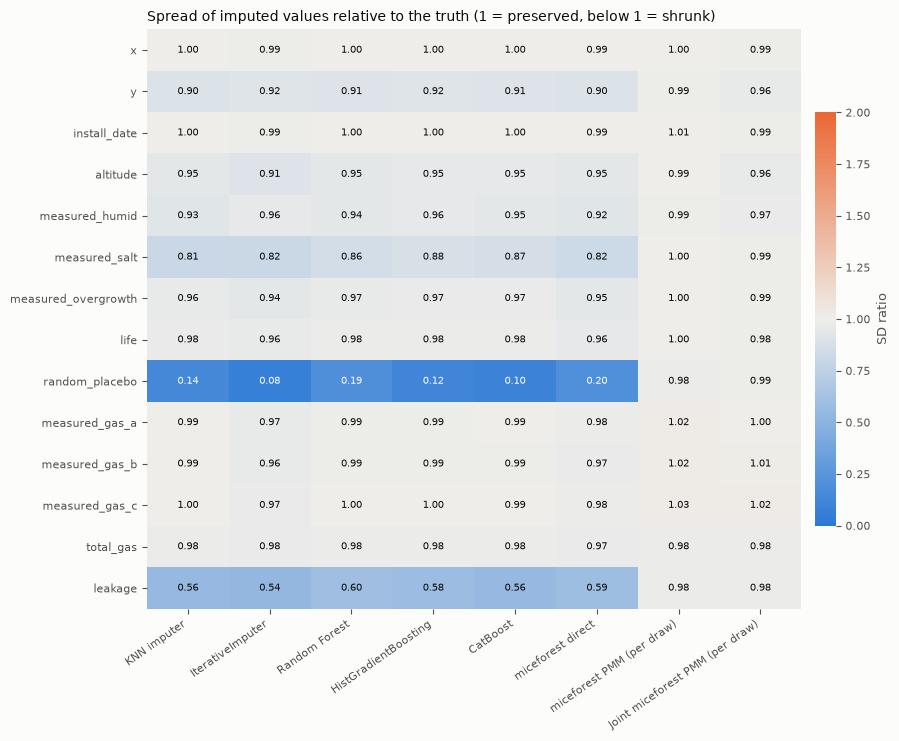

method,CatBoost,HistGradientBoosting,IterativeImputer,Joint miceforest PMM (per draw),KNN imputer,Median,Random Forest,miceforest PMM (per draw),miceforest direct
target,,,,,,,,,
x,0.1422,0.1101,0.2970,0.4891,0.1769,24.6844,0.1593,0.3438,0.2578
y,3.5384,3.1530,2.8101,1.3702,3.5732,24.8995,3.3439,0.6771,3.5768
install_date,2.4465,2.1455,4.3776,5.9570,2.5732,340.3193,2.6574,5.1727,3.4095
altitude,1.5813,1.5445,3.9025,1.3505,1.7941,33.4948,1.7106,0.9461,1.6569
measured_humid,0.0136,0.0113,0.0270,0.0080,0.0254,0.1725,0.0121,0.0053,0.0137
measured_salt,0.0336,0.0314,0.0549,0.0067,0.0537,0.2103,0.0377,0.0071,0.0427
measured_overgrowth,0.0153,0.0156,0.0334,0.0105,0.0244,0.2982,0.0174,0.0085,0.0199
life,7.9236,7.5298,15.1265,8.9052,10.4469,288.3616,8.4882,8.2136,15.0481
random_placebo,0.2313,0.2254,0.2352,0.0159,0.2203,0.2522,0.2083,0.0213,0.2086


,method,total variation,share gap 0,share gap 1,share gap 2,share gap 3
0,Mode,0.4366,0.3165,-0.2270,-0.2097,0.1201
1,KNN imputer,0.0015,-0.0005,0.0000,0.0015,-0.0010
2,Random Forest,0.0092,0.0010,-0.0036,-0.0056,0.0081
3,HistGradientBoosting,0.0031,-0.0020,0.0005,-0.0010,0.0025
4,CatBoost,0.0020,-0.0015,-0.0005,0.0005,0.0015
5,miceforest direct,0.0031,-0.0015,-0.0015,0.0020,0.0010
6,Joint miceforest PMM,0.0010,0.0000,0.0000,0.0010,-0.0010


In [33]:
distribution = ev.distribution_table(SCORED, DRAWS, STUDY.measured[REPRESENTATIVE], STUDY.truth[REPRESENTATIVE], STUDY.config)
distribution.to_csv(Path(STUDY.directory) / "distribution.csv", index=False)
fg.plot_spread(distribution, FIGURES)
display(distribution[distribution.scope.eq("missing cells")].pivot(index="target", columns="method", values="Wasserstein")
        .reindex(list(NUMERIC_TARGETS)).round(4))
display(ev.class_share_table(SCORED, STUDY.config).round(4))


### 7.2 Different fold splits

The representative scenario is repeated with two more fold seeds. The same rows are reused across seeds, so this shows sensitivity to the split and does not add new samples.

In [34]:
seed_numeric, seed_labels = ev.stability_table(NUMERIC, CATEGORY, STUDY.config)
print("Worst rank of each method across seeds:")
display(seed_numeric.pivot(index="target", columns="method", values="worst rank").reindex(list(NUMERIC_TARGETS))[list(NUMERIC_METHODS)])
seed_numeric["relative range"] = seed_numeric["MAE high"] / seed_numeric["MAE low"] - 1
print("Largest relative MAE range across seeds:", round(float(seed_numeric["relative range"].max()), 4))
display(seed_labels.round(4))


Worst rank of each method across seeds:


method,Median,KNN imputer,IterativeImputer,Random Forest,HistGradientBoosting,CatBoost,miceforest direct
target,,,,,,,
x,7.0,4.0,5.0,3.0,2.0,2.0,6.0
y,7.0,4.0,6.0,3.0,2.0,1.0,6.0
install_date,7.0,4.0,5.0,3.0,2.0,2.0,6.0
altitude,7.0,4.0,6.0,3.0,2.0,1.0,5.0
measured_humid,7.0,5.0,6.0,2.0,2.0,3.0,4.0
measured_salt,7.0,5.0,6.0,2.0,2.0,3.0,4.0
measured_overgrowth,7.0,4.0,6.0,3.0,1.0,2.0,5.0
life,7.0,5.0,6.0,3.0,1.0,3.0,5.0
random_placebo,1.0,6.0,2.0,7.0,4.0,3.0,7.0


Largest relative MAE range across seeds: 0.1242


,method,accuracy low,accuracy high,best rank,worst rank
0,Mode,0.2799,0.2824,6.0,6.0
1,KNN imputer,0.9766,0.9791,5.0,5.0
2,Random Forest,0.9786,0.9796,4.0,4.0
3,HistGradientBoosting,0.9807,0.9827,1.0,2.0
4,CatBoost,0.9791,0.9817,2.0,3.0
5,miceforest direct,0.9812,0.9837,1.0,3.0


### 7.3 Cost and warnings

Timings are single-threaded fits measured while other workers share the machine, so they are indicative only. A chained task covers many columns, so time is shown per target. The warning table lists each kind of warning once.

,experiment,method,tasks,fit seconds,predict seconds,seconds per target and fold
0,main,Median,630,6.072,0.801,0.011
1,main,Mode,45,0.490,0.057,0.012
2,stability,Median,140,1.347,0.175,0.011
3,stability,Mode,10,0.107,0.011,0.012
4,main,KNN imputer,45,5472.673,6881.869,18.303
5,stability,KNN imputer,10,1256.770,1532.139,18.593
6,ablation,KNN imputer,60,6101.902,7153.484,14.728
7,main,IterativeImputer,45,408.689,7.526,0.661
8,stability,IterativeImputer,10,91.218,1.602,0.663
9,budget,IterativeImputer (5),5,22.560,0.518,0.330


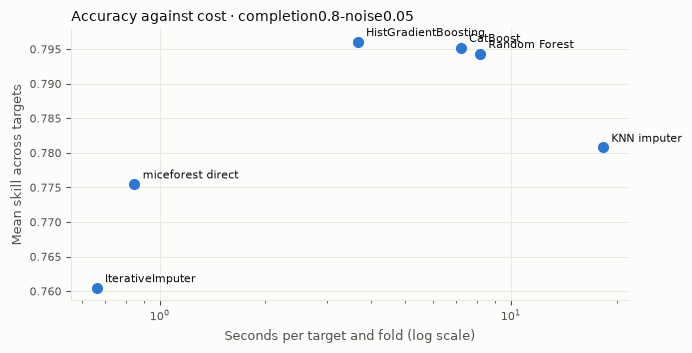

,method,warning_types,tasks,warning_example
0,IterativeImputer,ConvergenceWarning,115,[IterativeImputer] Early stopping criterion not reached.
1,IterativeImputer (5),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
2,IterativeImputer (30),ConvergenceWarning,5,[IterativeImputer] Early stopping criterion not reached.
3,Joint miceforest PMM,PerformanceWarning,5,"DataFrame is highly fragmented. This is usually the result of calling `frame.insert` many times, which has poor performance. Consider joining all columns at once using pd.concat(axis=1) instead. To"


In [35]:
display(STUDY.cost.round(3))
fg.plot_cost(STUDY.cost, NUMERIC, REPRESENTATIVE, FIGURES)
with pd.option_context("display.max_colwidth", None):
    display(ev.warning_table(STUDY.log))


## 8. Findings

The text below is written from this run's tables, so it changes with the data. It follows the study's three aims. The table after it gives the result for each target, where `lead` is `clear` when the gap to the next method is both separated and at least 5%. Changes refer to the same cells, and "not clear" means the 95% row-bootstrap interval includes zero.

In [36]:
display(Markdown(ev.findings(NUMERIC, CATEGORY, PAIRS, STUDY.effects, STUDY.relations, STUDY.links, STUDY.visibility,
                            STUDY.config)))
display(STUDY.targets.round(3))


**Model comparison**

- Highest mean skill in the representative scenario: HistGradientBoosting 0.796, CatBoost 0.795, Random Forest 0.794. Methods within 0.01 of the top are treated as tied.
- The best two methods cannot be separated on 13 of 13 numeric targets.
- `model_id` accuracy ranges from 97.8% to 98.4% across methods, against 28.1% for the mode.

**Relationships**

- With all defining inputs visible and no noise, the lowest errors are:
  - altitude from x and y: CatBoost, MAE 0.00841 against 34 for the median.
  - x from altitude and y: CatBoost, MAE 0.0839 against 24.7 for the median.
  - y from altitude and x: CatBoost, MAE 0.00861 against 25.3 for the median.
  - total_gas from gas readings: CatBoost, MAE 13.7 against 1.11e+03 for the median.
  - gas a from total and other readings: CatBoost, MAE 17.3 against 1.25e+03 for the median.
  - overgrowth from humidity and salt: CatBoost, MAE 0.00721 against 0.307 for the median.
  - life from all its inputs: HistGradientBoosting, MAE 10.8 against 295 for the median.
  - leakage from gases, date and model: Random Forest, MAE 0.0733 against 0.0969 for the median.
- Importance finds 73% to 82% of direct links, and 4% or less of relied-on columns have no link within two steps.
- Negative control: 0 of 54 comparisons with the median favour a method and 31 favour the median. The largest placebo skill is 0.0%.

**Failure conditions**

- Hidden inputs: for HistGradientBoosting, skill falls most on `y` (1.00 to 0.34), `measured_overgrowth` (0.95 to 0.43), `measured_salt` (0.71 to 0.20) when few linked columns are visible.
- Noise from lowest to highest: largest MAE changes for HistGradientBoosting are `total_gas` +153%, `measured_gas_c` +76%, `measured_gas_a` +75%.
- Completion from lowest to highest: largest MAE changes for HistGradientBoosting are `x` -87%, `install_date` -74%, `y` -73%.

,target,best,skill,next,gap to next,lead,noise 0 to 0.1,completion 0.7 to 0.9
0,x,HistGradientBoosting,0.984,CatBoost,0.080,not separated,+46%,-87%
1,y,CatBoost,0.821,HistGradientBoosting,0.012,not separated,+1% (not clear),-72%
2,install_date,HistGradientBoosting,0.979,CatBoost,0.048,not separated,+34%,-74%
3,altitude,CatBoost,0.869,HistGradientBoosting,0.017,not separated,+2% (not clear),-70%
4,measured_humid,Random Forest,0.753,HistGradientBoosting,0.008,not separated,+11%,-40%
5,measured_salt,HistGradientBoosting,0.581,Random Forest,0.008,not separated,+17%,-41%
6,measured_overgrowth,HistGradientBoosting,0.848,CatBoost,0.001,not separated,+40%,-63%
7,life,HistGradientBoosting,0.878,CatBoost,0.014,not separated,+55%,-66%
8,measured_gas_a,Random Forest,0.887,miceforest direct,0.013,not separated,+93%,-42%
9,measured_gas_b,Random Forest,0.861,CatBoost,0.010,not separated,+83%,-40%


### Limits

- The data is synthetic, and missingness is completely at random. Real gaps are likely to depend on the asset, which this study does not test.
- There is one generated truth table, so the study does not measure variation between generated datasets.
- `x` and `install_date` are near copies of each other, because assets were installed in grid order. High skill on these columns says little about model quality.
- A noise level does not mean equal difficulty across columns. At noise 0.1, noise is about 40% of the signal's spread for gas readings and under 10% for humidity, salt and overgrowth.
- The link from gas to `life` is weak by design, so missing it is not a clear model failure. `leakage` is only partly recoverable from the data.
- Importance comes from single-target models, not from the chained models that are scored. The ablation in section 6.8 tests chained models directly.
- All development used this one dataset. Settings never saw a hidden cell, but no independent dataset was held back.
- Shared settings were chosen on three scenarios and may not be the best elsewhere. The search covered a fixed list of candidates, so it does not establish any method's ceiling.
- A shared setting cannot suit every column. Chained models trade a little accuracy on some columns for one consistent fit.
- The candidates were written by people who knew how the data was generated. Models receive no relationship and a fixed rule made the final choice, but second-order terms were offered because such relationships were expected.
- A chained model trains on estimates that used the row's own label, which is not available for a hidden cell. Removing this effect improved the selection score by 0.25%, so the simpler form was kept.
- Row intervals are conditional on fitted models. Neighbouring grid rows are related, so intervals may be narrower than they should be.
- `life`, `total_gas` and `leakage` are exact by design, so results for and from these columns are better than noisy measurements would allow.

### Saved results

The last cell writes one completed table per method to the run folder and summarises the run.

In [37]:
completed = ev.export_completions(SCORED, STUDY.measured[REPRESENTATIVE], REPRESENTATIVE, Path(STUDY.directory) / "completed")
display(completed)
display(ev.run_summary(STUDY.log, STUDY.plan))
print("Run folder:", STUDY.directory)
print("To repeat the evaluation, set EVALUATION_RUN_ID to:", Path(STUDY.directory).name)


,method,file,cells still missing
0,Median,Median.csv,0
1,KNN imputer,KNN_imputer.csv,0
2,IterativeImputer,IterativeImputer.csv,1965
3,Random Forest,Random_Forest.csv,0
4,HistGradientBoosting,HistGradientBoosting.csv,0
5,CatBoost,CatBoost.csv,0
6,miceforest direct,miceforest_direct.csv,0


,planned tasks,finished tasks,succeeded,failed,tasks with warnings
0,1580,1580,1580,0,130


Run folder: C:\Users\Morgan\Desktop\Capstone Project\gh\team19-asset-data\outputs\imputation-study\runs\20261105-234621
To repeat the evaluation, set EVALUATION_RUN_ID to: 20261105-234621
